**Program name:** GNS1 - Applications of generative models to enhance the performance of complex probabilistic seismic models

**Student names - IDs:**

  - Martin Nguyen - 68623131
  - Jian Di - 61972461

**Descriptions:**  To reduce the complexity of probabilistic seismic models as well as the amount of computation time and operation work from Open Quake Engine - a well-known Probabilistic Seismic Hazard Analysis (PSHA) model, this three-month project proposed to apply a Generative Adversarial Network (GAN) model - Conditional Tabular Generative Adversarial Network (CTGAN) model. The idea was that the CTGAN model will learn the underlying features from a small sample (about 10-20%) of the entire outputs produced by OpenQuake Engine to generate a similar outcome. The performance would be measured by several different evaluation methods to see how the similarity would be. There would be 3 script reports:
- The script report 1 - Main script for the project
- The script report 2 - PGA transformation according to the Project Advisor
- The script report 3 - Trying the script on the full dataset

This is the script report 1. It would include the full explanation. The other script reports included only the codes with brief explanation at the beginning.

--------------------------------------------------------------------------------

**DATA ETHICS**

Before building up the codes and process the project, the data ethics were checked through the checklist below (please visit [here](https://deon.drivendata.org/) for more information). Also, three policies from the University were referred, they were:
- Data Management Policy (please visit [here](https://www.canterbury.ac.nz/media/uc-policy-library/general/Data-Management-Policy.pdf))
- Research Conduct Policy (please visit [here](https://www.canterbury.ac.nz/media/uc-policy-library/student/Research-Conduct-Policy.pdf))
- Storage (please visit [here](https://www.canterbury.ac.nz/its/knowledge-base/storage/))

The below was checklist from deon website.

In [ ]:
# Installing deon
!pip install deon

In [ ]:
# Creating checklist file
!deon -o ETHICS_CHECKLIST.md

Checklist successfully written to file ETHICS_CHECKLIST.md.


In [ ]:
# Calling out the file
!cat ETHICS_CHECKLIST.md

# Data Science Ethics Checklist

[![Deon badge](https://img.shields.io/badge/ethics%20checklist-deon-brightgreen.svg?style=popout-square)](http://deon.drivendata.org/)

## A. Data Collection
 - [ ] **A.1 Informed consent**: If there are human subjects, have they given informed consent, where subjects affirmatively opt-in and have a clear understanding of the data uses to which they consent?
 - [ ] **A.2 Collection bias**: Have we considered sources of bias that could be introduced during data collection and survey design and taken steps to mitigate those?
 - [ ] **A.3 Limit PII exposure**: Have we considered ways to minimize exposure of personally identifiable information (PII) for example through anonymization or not collecting information that isn't relevant for analysis?
 - [ ] **A.4 Downstream bias mitigation**: Have we considered ways to enable testing downstream results for biased outcomes (e.g., collecting data on protected group status like race or gender)?

## B. Data Storage


--------------------------------------------------------------------------------

**NOTICE: The results we gained below might ONLY correct for this version of SUB-DATASET.**

The script below would be processed based on the diagram below:

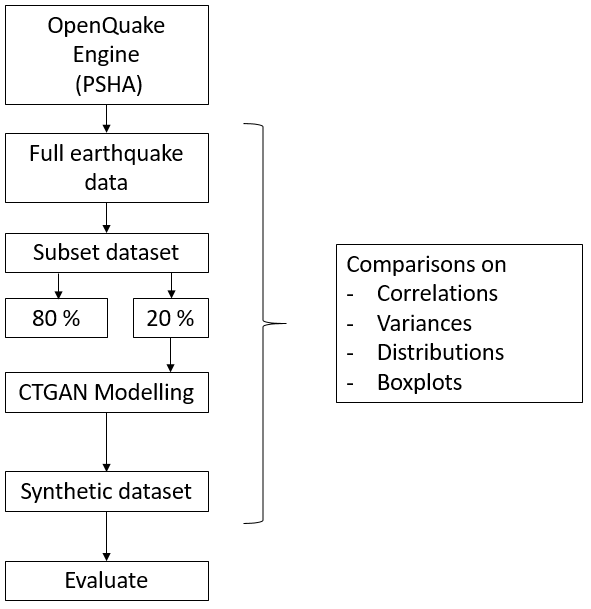

We would load the data produced from OpenQuake Engine, extract the sub-dataset (this process was due to the limited memory of Google Colab to run the big size of data), train model with ctgan package to get the synthetic data, then do the evaluation. Particularly, the structure was summarised and organised in details as below:

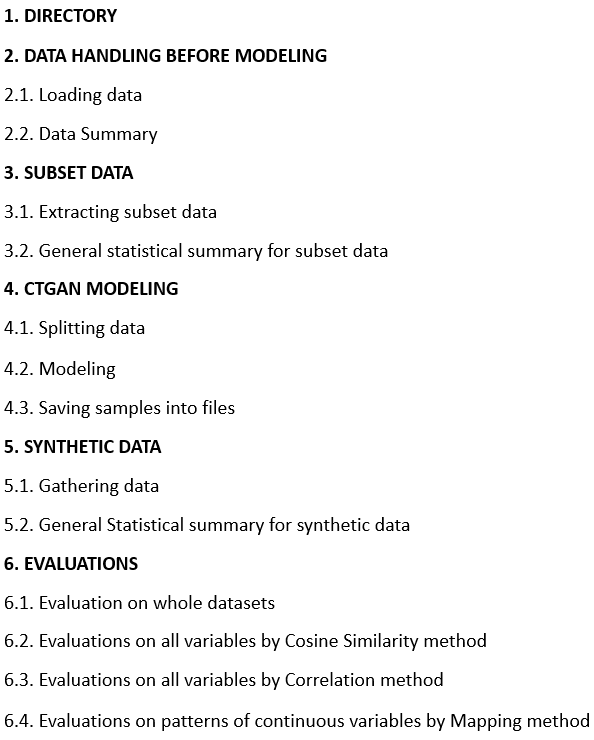

Next, we would start to walk through the code. Before running the code below, there were some notices about ctgan packages. 
- The version of ctgan package used for modeling was 0.2.2
- The version of sdv package used for evaluation was 0.6.1
- The sdv package included the newest version of ctgan package which was 0.3.1. We did not use this version of ctgan for modeling. Therefore, to avoid the confusion of using ctgan package in the system, the sdv version 0.3.1 should only be installed ONLY ONCE and should be installed AFTER ctgan version 0.2.2. In particular, for the very first time to run the code, there would be error after installing sdv, COMMENTING these lines of code immediately after that would be required. Next, all the other codes should be run as normal.

# **1. DIRECTORY**

The code should be run when the GPU was turned on, if not, it would take very long time to let the model get trained. Also, to have this version of code, we have used up to 7 gmail accounts due to the limited usage of the free version of Google Colab. Please see [here](https://medium.com/@oribarel/getting-the-most-out-of-your-google-colab-2b0585f82403#:~:text=Using%20GPU,up%20to%2012%20hours%20continuously.&text=To%20do%20this%20go%20to,there%20is%20no%20GPU%20available.) for more information.

In [ ]:
# Checking if GPU was on
import tensorflow as tf
tf.test.gpu_device_name()

'/device:GPU:0'

If the result was ' ', it meant CPU. If the result was '/device:GPU:0', it meant GPU. After this, we would access to the Google Drive. Before processing the code below, some of folders should be stored and created in Google Drive. In particular:
- A folder named 'Earthquake' should be created in Google Drive (My Drive/Earthquake)
- In the 'Earthquake' folder, 'for_Martin_and_Jian' folder from this [link](https://www.dropbox.com/sh/vmst2jyz61x9mzn/AAD7KNKBJqqHeMqG480cKjCba?dl=0) should be stored here. This included all of the necessary csv files for this script.
- Also, a folder for output/synthetic data named 'CTGAN_epochs200' should be created inside of 'for_Martin_and_Jian' folder too.

In [ ]:
# Accessing to Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Changing the directory
%cd /content/drive/My\ Drive/Earthquake/for_Martin_and_Jian

# Building up the output directory
from pathlib import Path
output_directory = Path('/content/drive/My Drive/Earthquake/for_Martin_and_Jian')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/My Drive/Earthquake/for_Martin_and_Jian


After accessing to the Google Drive, the directory was changed into the folder contained the dataset (here was 'for_Martin_and_Jian'). The output directory was also set to this folder as 'CTGAN_epochs200' was stored here.

Next we would load and process on the data.

# **2. DATA HANDLING BEFORE MODELING**

## 2.1. Loading data

In [ ]:
# Loading csv file
import pandas as pd
HawkesBay_data_full = pd.read_csv("OQ_data_HawkesBay_region.csv")

# Checking data
HawkesBay_data_full

,Unnamed: 0,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0,lon,lat
0,0,0,1244.0,0.010817,530.593,0.915348,90.217180,177.362655,-38.809237
1,1,0,1256.0,0.010859,635.389,0.744794,46.398606,177.482655,-38.809237
2,2,0,1261.0,0.010780,1000.000,0.443316,8.266183,177.532655,-38.809237
3,3,0,1466.0,0.010998,1000.000,0.443316,8.266183,177.592655,-38.829237
4,4,0,1561.0,0.013426,1000.000,0.443316,8.266183,177.472655,-38.839237
...,...,...,...,...,...,...,...,...,...
1927169,1927169,996,9186.0,0.011678,1000.000,0.443316,8.266183,176.192655,-39.459237
1927170,1927170,996,9195.0,0.011773,1000.000,0.443316,8.266183,176.282655,-39.459237
1927171,1927171,996,9199.0,0.014754,1000.000,0.443316,8.266183,176.322655,-39.459237
1927172,1927172,996,9200.0,0.012995,1000.000,0.443316,8.266183,176.332655,-39.459237


Looking at the data table generally, we could see the dataset had several types of data and missing value(s) in this dataset. Additionally, the first column name should be changed into 'order' as it was the order column for each observation. Following this, we would have clearer look in the next section.

## 2.2. Data summary

In [ ]:
# Changing the name of the first column into order
HawkesBay_data_full = HawkesBay_data_full.rename(columns={'Unnamed: 0': 'order'})

# Checking details of data
HawkesBay_data_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1927174 entries, 0 to 1927173
Data columns (total 9 columns):
 #   Column    Dtype  
---  ------    -----  
 0   order     int64  
 1   event_id  int64  
 2   site_id   float64
 3   gmv_PGA   float64
 4   Vs30      float64
 5   Z2.5      float64
 6   Z1.0      float64
 7   lon       float64
 8   lat       float64
dtypes: float64(7), int64(2)
memory usage: 132.3 MB


As the results, we saw that: 
- There were 9 variables (2 integer variables, 7 float variables)
- There were 1927174 observations


### 2.2.1. Missing values

In [ ]:
# Checking missing values
num_missing = HawkesBay_data_full.isnull().values.sum()
print('Number of missing values: ', num_missing)

# Displaying missing values (if any)
HawkesBay_data_full[pd.isnull(HawkesBay_data_full["site_id"])]

Number of missing values:  7


,order,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0,lon,lat
1927173,1927173,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN


It seemed like we have only one observation having missing value. This case could be seen as missing completely at random (MCAR) since there was no relationship between the missingness with other observations as well as variables. Also, the ratio between the number of missing observations and whole number of observation was very small (1/1927174). Therefore, removing this observation would not cause any unbiased situations and would not lead to a weaker training set. Following this, removing the missing observation would be done as below.

In [ ]:
# Removing the missing value
HawkesBay_data_full = HawkesBay_data_full.drop([1927173])

# Checking data
HawkesBay_data_full.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1927173 entries, 0 to 1927172
Data columns (total 9 columns):
 #   Column    Dtype  
---  ------    -----  
 0   order     int64  
 1   event_id  int64  
 2   site_id   float64
 3   gmv_PGA   float64
 4   Vs30      float64
 5   Z2.5      float64
 6   Z1.0      float64
 7   lon       float64
 8   lat       float64
dtypes: float64(7), int64(2)
memory usage: 147.0 MB


### 2.2.2. Correlation

At first, we created a function to show the correlation matrix heatmap of a dataframe.

In [ ]:
# Creating function to show the correlation matrix heatmap of a dataframe
# Importing seaborn and matplotlib for using heatmap
import seaborn as sns
import matplotlib.pyplot as plt

# Creating function
def corr_heatmap(df, title):
  '''This function is to show the correlation matrix heatmap of a dataframe.
  For more details please visit: https://datatofish.com/correlation-matrix-pandas/
                                 https://datascience.stackexchange.com/questions/17540/make-seaborn-heatmap-bigger 
  Arguments:
            df:
              Dataframe needs to calculate the correlation matrix
            title:
              Name of the dataframe
  '''
  plt.figure(figsize=(10,10))
  sns.heatmap(df.corr(), annot_kws={"size": 15}, annot=True, cmap="YlGnBu").set_title(f'Correlation matrix of {title}')
  plt.show()

Next, we would show the correlation matrix of full dataset.

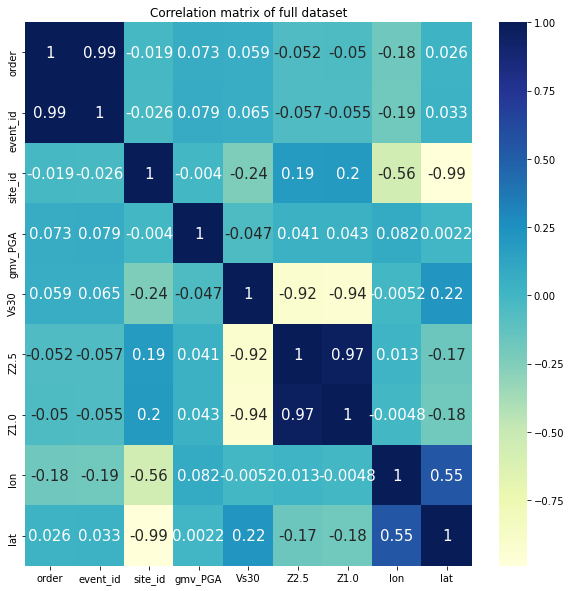

In [ ]:
# Checking correlation
corr_heatmap(HawkesBay_data_full, 'full dataset')

As the result, there seemed to be three correlation cases in this dataset:
- Strong positive correlation between order and event_id. However, in the later process, order column would not be used for generating a synthetic data. The full explanation would be described later in this script report
- Strong negative correlation between site_id and lat. However, in the later process, lat column would not be used in modelling. The full explanation would be described later in this script report
- Strong negative correlation between Vs30 and Z2.5
- Strong negative correlation between Vs30 and Z1.0
- Strong positive correlation between Z2.5 and Z1.0

We would see if the ctgan model could capture this feature

### 2.2.3. Variances

We would not check variance on order variable as this was used as ID for observations.

In [ ]:
# Checking variance of variables
print('Variance of event_id: ', HawkesBay_data_full.var()['event_id'])
print('Variance of site_id: ', HawkesBay_data_full.var()['site_id'])
print('Variance of PGA: ', HawkesBay_data_full.var()['gmv_PGA'])
print('Variance of Vs30: ', HawkesBay_data_full.var()['Vs30'])
print('Variance of Z2.5: ', HawkesBay_data_full.var()['Z2.5'])
print('Variance of Z1.0: ', HawkesBay_data_full.var()['Z1.0'])
print('Variance of lon: ', HawkesBay_data_full.var()['lon'])
print('Variance of lat: ', HawkesBay_data_full.var()['lat'])

Variance of event_id:  70395.65112233695
Variance of site_id:  21939811.517852794
Variance of PGA:  0.0004955774281478562
Variance of Vs30:  69194.80803572982
Variance of Z2.5:  0.3905959643205111
Variance of Z1.0:  11291.573466304819
Variance of lon:  0.19675849272752186
Variance of lat:  0.2188909648144187


We could use just simple line of code as below to see all the variances of variables

```
HawkesBay_data_full.var()
```
However, it would be hard to see the full float numbers of them. Therefore, we used the code for each variable to see the details. As the results, we could see that:
- Variables event_id, site_id, Vs30, Z1.0 have very high variances
- Variables PGA, Z2.5, lon, lat have very low variances, especially PGA close to 0.


### 2.2.4. Distributions



Text(0.5, 0.98, 'Distribution of variables in full dataset')

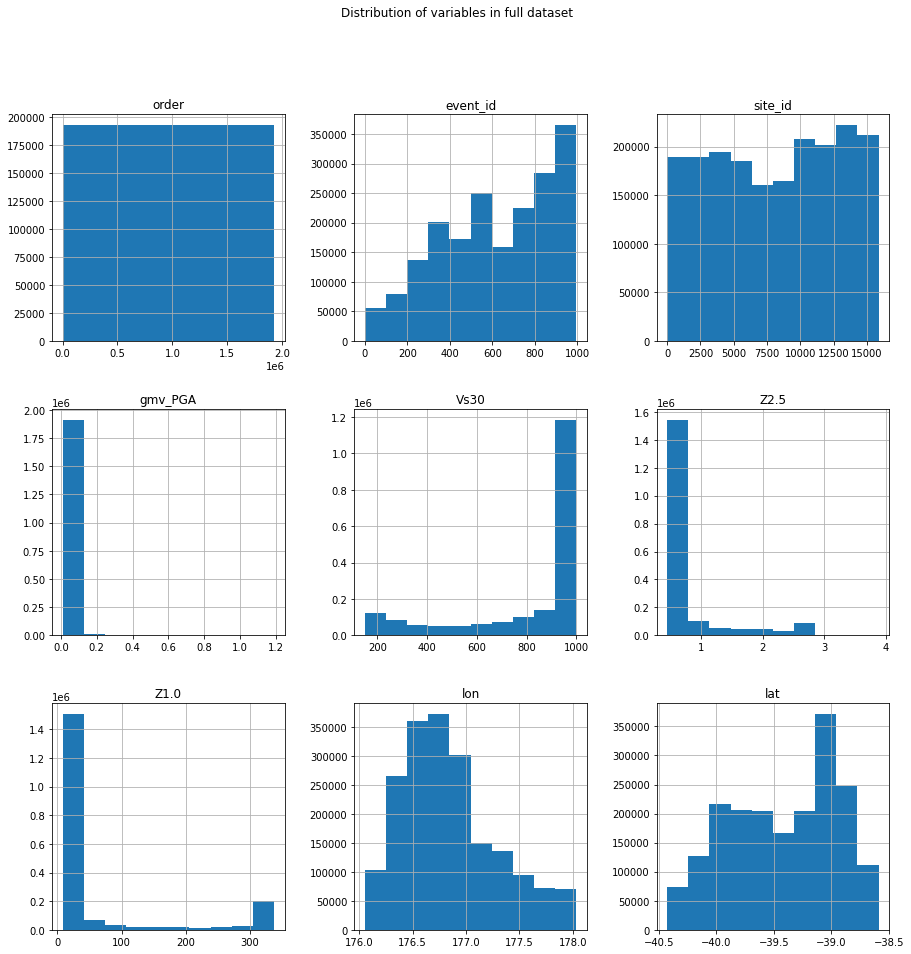

In [ ]:
# Checking distributions
HawkesBay_data_full.hist(figsize=(15, 15))
plt.suptitle('Distribution of variables in full dataset')

As we noticed at PGA variable, it seemed like all the values of this variable stayed around value 0 which could explain the very low variances. In other word, we could see PGA variable as an almost constant variable at value of 0. Following this, we would check if the ctgan model could learn this unique feature and other variables's distributions.

### 2.2.5. Other statistical summary

In this section, we would check the descriptive summary and boxplots at the same time.

In [ ]:
# Checking the general statistical summary
HawkesBay_data_full.drop(columns=['order']).describe()

,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0,lon,lat
count,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06
mean,6.201857e+02,8.168213e+03,2.530335e-02,8.239278e+02,7.451369e-01,5.977937e+01,1.768460e+02,-3.941956e+01
std,2.653218e+02,4.683995e+03,2.226157e-02,2.630491e+02,6.249768e-01,1.062618e+02,4.435747e-01,4.678578e-01
min,0.000000e+00,0.000000e+00,1.000000e-02,1.500000e+02,4.433162e-01,8.266183e+00,1.760527e+02,-4.042924e+01
25%,4.010000e+02,4.050000e+03,1.299682e-02,7.252880e+02,4.433162e-01,8.266183e+00,1.765127e+02,-3.981924e+01
50%,6.260000e+02,8.394000e+03,1.804735e-02,9.883010e+02,4.493247e-01,8.646085e+00,1.767727e+02,-3.935924e+01
75%,8.510000e+02,1.234400e+04,2.882650e-02,1.000000e+03,6.401615e-01,2.812550e+01,1.770927e+02,-3.901924e+01
max,9.960000e+02,1.587700e+04,1.188596e+00,1.000000e+03,3.883874e+00,3.374264e+02,1.780327e+02,-3.858924e+01


In [ ]:
# Creating function to show the boxplots of variables in a dataframe at the same time
# Importing seaborn and matplotlib
import seaborn as sns
import matplotlib.pyplot as plt

# Creating function
def full_boxplots(df, whisker, title):
  '''This function is to show the boxplots of variables in a dataframe at the same time
  For more details please visit: https://seaborn.pydata.org/generated/seaborn.boxplot.html 
  Arguments:
            df:
              Dataframe having variables needs to show the boxplots
            whisker:
              Proportion of the IQR past the low and high quartiles to extend the plot whiskers. 
              Points outside this range will be identified as outliers
            title:
              Name of dataframe
  '''
  plt.figure(figsize=(10,10))
  sns.boxplot(data=df, whis=whisker).set_title(f'Boxplots of {title}')
  plt.show()

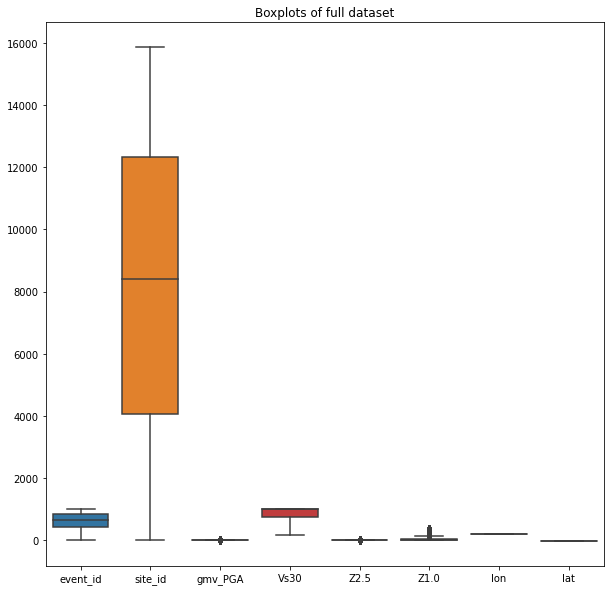

In [ ]:
# Checking the boxplots
full_boxplots(HawkesBay_data_full.drop(columns=['order']), 5, 'full dataset')

As the PGA, Vs30, Z2.5, Z1.0, longitude and latitude were not seen clearly on the boxplots above, they would be drew again as below.

At below, we would create a function to produce the boxplots of PGA, Vs30, Z2.5 and Z1.0 with the changing of dataframe and whisker. This process would help us to figure out the outliers clearer.

In [ ]:
# Creating function to show the boxplots of each variables in a dataframe
# Importing seaborn and matplotlib
import seaborn as sns
import matplotlib.pyplot as plt

# Creating function
def each_boxplot(df, whisker, lonlat):
  '''This function is to show the boxplots of each variables in a dataframe.
  For more details please visit: https://seaborn.pydata.org/generated/seaborn.boxplot.html 
  Arguments:
            df:
              Dataframe having variables needs to show the boxplots
            whisker:
              Proportion of the IQR past the low and high quartiles to extend the plot whiskers. 
              Points outside this range will be identified as outliers
            lonlat ('y' or 'n'):
              y - yes for showing the boxplots of longitude and latitude
              n - no for showing the boxplots of longitude and latitude
  '''
  if lonlat == 'y':
    # if longitude and latitude needs showing the boxplots
    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(10, 15))

    sns.boxplot(data=df[['gmv_PGA']], whis=whisker, ax=axes[0,0]).set_title(f'Boxplot of PGA')
    sns.boxplot(data=df[['Vs30']], whis=whisker, ax=axes[0,1]).set_title(f'Boxplot of Vs30')
    sns.boxplot(data=df[['Z2.5']], whis=whisker, ax=axes[1,0]).set_title(f'Boxplot of Z2.5')
    sns.boxplot(data=df[['Z1.0']], whis=whisker, ax=axes[1,1]).set_title(f'Boxplot of Z1.0')
    sns.boxplot(data=df[['lon']], whis=whisker, ax=axes[2,0]).set_title(f'Boxplot of longitude')
    sns.boxplot(data=df[['lat']], whis=whisker, ax=axes[2,1]).set_title(f'Boxplot of latitude')
  else:
    # if longitude and latitude not need showing the boxplots
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 15))

    sns.boxplot(data=df[['gmv_PGA']], whis=whisker, ax=axes[0,0]).set_title(f'Boxplot of PGA')
    sns.boxplot(data=df[['Vs30']], whis=whisker, ax=axes[0,1]).set_title(f'Boxplot of Vs30')
    sns.boxplot(data=df[['Z2.5']], whis=whisker, ax=axes[1,0]).set_title(f'Boxplot of Z2.5')
    sns.boxplot(data=df[['Z1.0']], whis=whisker, ax=axes[1,1]).set_title(f'Boxplot of Z1.0')


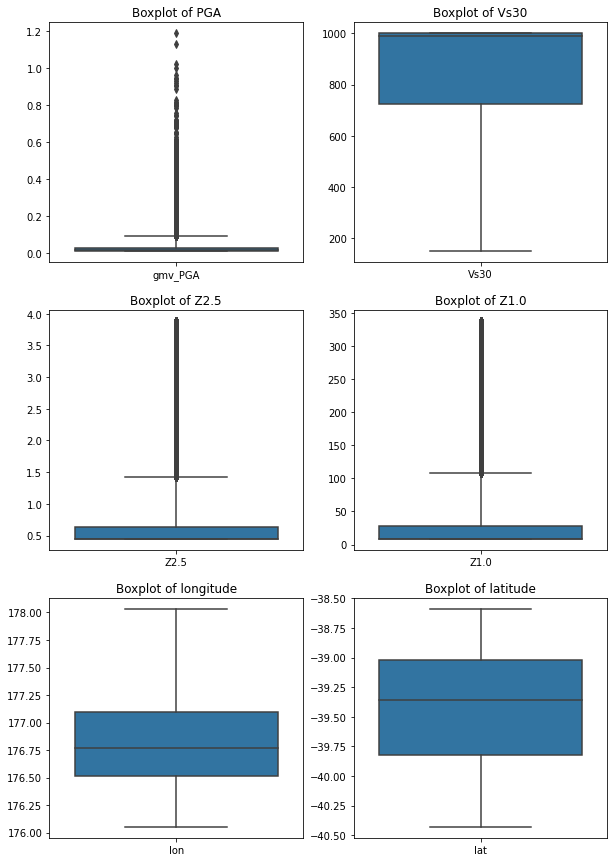

In [ ]:
each_boxplot(HawkesBay_data_full, 5, 'y')

Combining three results above, we could notice that:
- site_id had the largest range of values
- When changing the number of whisker from 1.5 to 5, only variables PGA, Z2.5, and Z1.0 seemed to have outliers.
- PGA values seemed to be very close to 0.
- All the variables had their own range of values

We would see if ctgan model can learn all of them.

# **3. SUB-DATASET**

The script was tried with a lot of versions with different settings as below:
- Setting1: Sample fraction=0.1, removing 'order' column, discrete_columns=['event_id'], epoch=100

   ==> The correlation of site_id with event_id, Vs30, Z2.5, and Z1.0 were high (all around 0.9). The model could not learn the features of PGA. Also, the ctgan model could not learn the boundaries of the Hawke's Bay's shape through longitude and latitude.

- Setting2: Sample fraction=0.01, removing 'order' column, changing site_id into integer, discrete_columns=['site_id', 'event_id'], epoch=80

    ==> The correlation of site_id with event_id, Vs30, Z2.5, and Z1.0 were lower (all around 0.8). The model could not learn the features of PGA. However, the code got crashed if the number of epoch was increased. Therefore, we did not know if we increased the number of epoch, the results would get better or not. Additionally, the ctgan model could not learn the boundaries of the Hawke's Bay's shape through longitude and latitude.

- Setting3: Sample fraction=0.01, keeping all variables as they are, discrete_columns=['event_id', 'order']

    ==> The code kept crashing

- Setting4: Sample fraction=0.01, removing order, lon, lat columns (merging with sitemesh_133.csv file later), converting 'site_id' from float to integer, discrete_columns = ['event_id', 'site_id'], epoch = 500

    ==> The model could learn some patterns

The reason for the code keeping crashing was due to the limited memory of Google Colab. Through the results of these settings and discussion with Robert from GNS team, we decided to minimise the data size and to go further with setting 4 but with some changes. In particular,
- We reduced the data size by putting boundaries on longitude and latitude. We had planned to choose the boundaries which could mostly represent the whole dataset. However, there would still be some features that the smaller data could not cover. Hence, in this version, we would select the most alike boundaries to complete the procedure of coding, then we would choose the other different boundaries including different patterns. Through this way, the data could be assessed thoroughly.
- We used the sample fraction around 0.1 and 0.2
- We removed 'order' column, at first, because this data was ID variable and did not help much for ctgan learning. Secondly, this data was not extracted from Open Quake Engine. Thirdly, we could save more space for Google Colab memory. Fourthly, we could use the site_id as an ID variable or key variable for later usage.
- We removed the longitude and the latitude ONLY in the data we used for modeling because the model could not learn the shape of Hawke's Bay area. After that, we would merge the synthetic data produced from the ctgan model with the 'sitemesh_133.csv' file containing site_id, longitude, and latitude.
- We converted site_id format from float to integer. To explain, if we kept site_id as float, the synthetic data would contain the float numbers for this variable which would make it impossible to merge with the 'sitemesh_133.csv' later. Also, the site_id should be kept as integer as this is the ID variable for both longitude and latitude.
- We kept the number of epoch at around 100 and 200 to see if the ctgan model could still learn well with these small quantities. 

## 3.1. Extracting sub-dataset

In [ ]:
# Extracting only small area
# Latitude: -39.70 <= lat <= -39.40
# Longitude: 176.55 <= lon <= 177.90
HawkesBay_data = HawkesBay_data_full[(HawkesBay_data_full['lat']>=-39.70) & 
                                     (HawkesBay_data_full['lat']<=-39.40) & 
                                     (HawkesBay_data_full['lon']>=176.55) & 
                                     (HawkesBay_data_full['lon']<=176.90)]

# Removing 'order' column                                    
HawkesBay_data = HawkesBay_data.drop(columns=["order"])

# Converting site_id format from float to integer
HawkesBay_data.site_id = HawkesBay_data.site_id.astype(int)

The part above could be changed into other locations of Hawke's Bay by changing the longitude and latitude.

In [ ]:
# Dropping off longitude and latitude for modelling then merging later
HawkesBay_data_droplonlat = HawkesBay_data.drop(columns=['lon', 'lat'])

# Checking data
HawkesBay_data_droplonlat.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 145756 entries, 138 to 1927161
Data columns (total 6 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   event_id  145756 non-null  int64  
 1   site_id   145756 non-null  int64  
 2   gmv_PGA   145756 non-null  float64
 3   Vs30      145756 non-null  float64
 4   Z2.5      145756 non-null  float64
 5   Z1.0      145756 non-null  float64
dtypes: float64(4), int64(2)
memory usage: 7.8 MB


As we could see, with smaller data, we had:
- 145756 observations
- 6 variables would be used for training models. In that, 2 integers and 4 floats.

Now we would check the distributions, variances and other statistical summary of this small data to see if it was good to be used as a representative for the whole data.

## 3.2. General statistical summary for sub-dataset

The checkings below would follow the order of the checkings done with whole data. In particular, the order of checking process would be:
1. Correlation
2. Variances
3. Distributions
4. Descriptive summary
5. Boxplots

Only in correlation section, we would use the dataset included the longitude and latitude. To explain, these geometric variables would not be used in modelling, but the latitude had strong negative correlation with the site_id. Hence, this feature would only need checking in correlation section.

### 3.2.1. Correlation

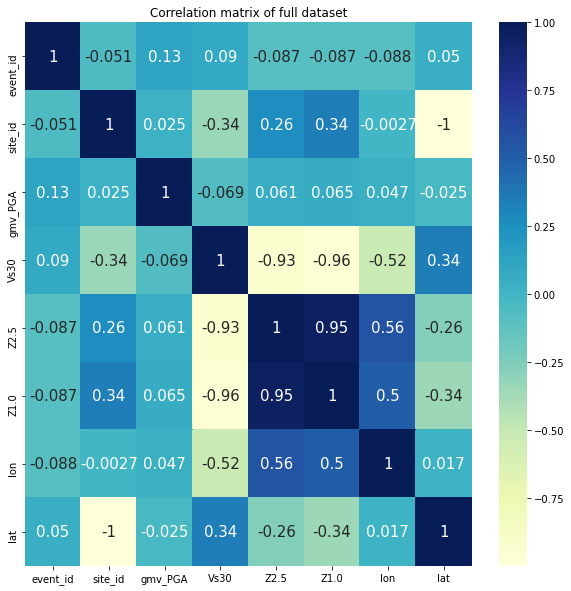

In [ ]:
# Checking correlation
corr_heatmap(HawkesBay_data, 'full dataset')

It seemed like the sub-dataset was still able to represent the correlations among Vs30, Z2.5 and Z1.0. In particular,
- Strong negative correaltion between site_id and lat
- Strong negative correlation between Vs30 and Z2.5
- Strong negative correlation between Vs30 and Z1.0
- Strong positive correlation between Z2.5 and Z1.0

### 3.2.2. Variances

In [ ]:
# Checking the variances of the small data
HawkesBay_data_droplonlat.var()

event_id     69124.935695
site_id     494605.364514
gmv_PGA          0.000396
Vs30        105073.882663
Z2.5             1.039278
Z1.0         22313.664402
dtype: float64

It seemed like the sub-dataset was still able to represent some variances. In particular,
- Variables event_id, site_id, Vs30, Z1.0 had very high variances
- Variables PGA, Z2.5, lon, lat had very low variances, especially PGA was close to 0.

### 3.2.3. Distributions

Text(0.5, 0.98, 'Distribution of variables in subset dataset')

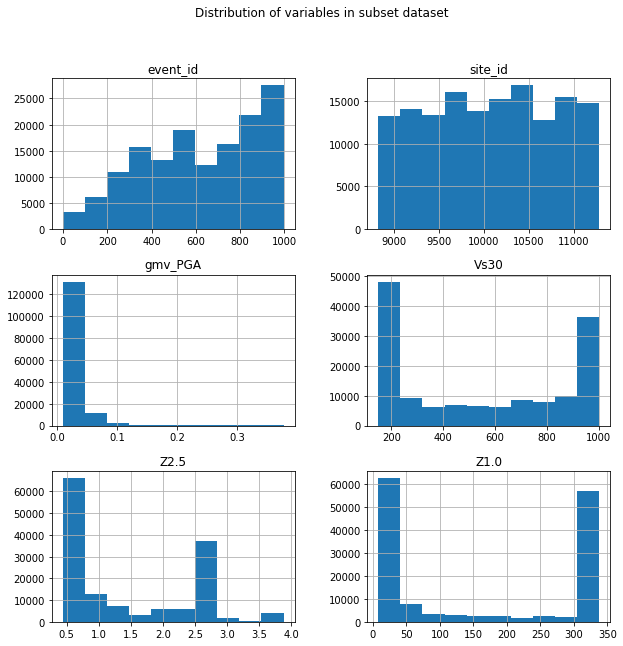

In [ ]:
# Checking the distributions of the small data
HawkesBay_data_droplonlat.hist(figsize=(10, 10))
plt.suptitle('Distribution of variables in sub-dataset')

The distributions of the sub-dataset seemed to represent well enough for the whole dataset, except:
- The site_id seemed to have a bit different in the middle of the distribution from the whole data.
- The PGA and Z2.5 seemed to have a little bit wider range of values than the whole data.
- Vs30 and Z1.0 seemed to have a bit different at two tails of the distribution from the whole data.

### 3.2.4. Other statistical summary

In [ ]:
# Checking the general statistical summary
HawkesBay_data_droplonlat.describe()

,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0
count,145756.000000,145756.000000,145756.000000,145756.000000,145756.000000,145756.000000
mean,621.276318,10076.617731,0.024710,559.461941,1.438027,162.575267
std,262.916214,703.281853,0.019898,324.151018,1.019450,149.377590
min,0.000000,8827.000000,0.010000,150.000000,0.443316,8.266183
25%,402.000000,9484.000000,0.012934,210.000000,0.492182,11.717860
50%,626.000000,10106.000000,0.017909,528.542000,0.919413,91.475169
75%,851.000000,10693.000000,0.028498,912.650000,2.642985,336.092436
max,996.000000,11280.000000,0.377790,1000.000000,3.883874,337.426407


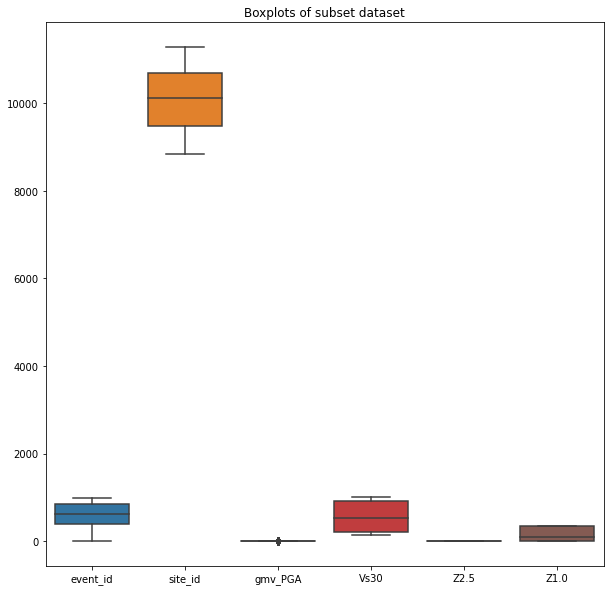

In [ ]:
# Checking the boxplots
full_boxplots(HawkesBay_data_droplonlat, 5, 'sub-dataset')

As the PGA, Vs30, Z2.5 and Z1.0 were hard to observe on the boxplot above, the boxplots of those variables would be seen clearer as below.

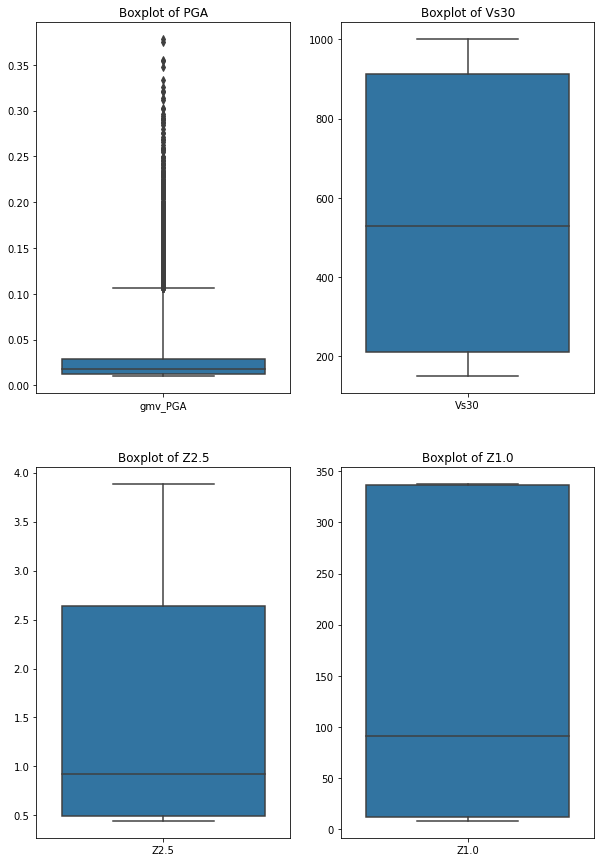

In [ ]:
# Checking boxplots for other variables except event_id and site_id
each_boxplot(HawkesBay_data_droplonlat, 5, 'n')

As we noticed from the above results, Z2.5 and Z1.0 did not have outliers as they had in the full dataset.

Based on the above results, despite some small differences, this sub-dataset still represented well enough. Therefore, instead of keeping looking for another sub-dataset which can perfectly represent the original one, to save time, we would work on this sub-dataset just to see if the CTGAN model could learn any clusters or patterns of values. After that, if we might still have time for this project we would go futher with other subset data that might contain this outliers feature.

Apart from many similar points listed above, this sub-dataset were chosen also because of the clear patterns. Following this, these patterns could be seen clearly on maps and we could use it as the assessment for the similarity based on vision when we compared the original data and the synthetic one.

# **4. CTGAN MODELING**



## 4.1. Splitting data

In [ ]:
# Getting the training sample (20%)
trainingSample = HawkesBay_data_droplonlat.sample(frac=.2)

# Checking data
trainingSample.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 29151 entries, 721180 to 1872295
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   event_id  29151 non-null  int64  
 1   site_id   29151 non-null  int64  
 2   gmv_PGA   29151 non-null  float64
 3   Vs30      29151 non-null  float64
 4   Z2.5      29151 non-null  float64
 5   Z1.0      29151 non-null  float64
dtypes: float64(4), int64(2)
memory usage: 1.6 MB


## 4.2. Modeling

There were 12 versions of GAN models that we tried (updated to 04-01-2021):
- Model1: Separate CTGAN package version 0.2.2 - using CTGANSynthesizer
- Model2: Separate CTGAN pakage version 0.3.0 - using CTGANSynthesizer
- Model3: Separate CTGAN package version 0.3.1 - using CTGANSynthesizer
- Model4: Attached CTGAN package version 0.2.2 - using CTGAN in SDV package version 0.5.0
- Model5: Attached CTGAN package version 0.3.0 - using CTGAN in SDV package version 0.6.0
- Model6: Attached CTGAN package version 0.3.1 - using CTGAN in SDV package version 0.6.1
- Model7: Attached CopulaGAN package - using CopulaGAN in SDV package version 0.5.0
- Model8: Attached CopulaGAN package - using CopulaGAN in SDV package version 0.6.0
- Model9: Attached CopulaGAN package - using CopulaGAN in SDV package version 0.6.1

In the SDV package there is another model that could do the same job as GAN model which is GaussianCopula, we also tried:
- Model10: Attached GuassianCopula package - using GuassianCopula in SDV package version 0.5.0
- Model11: Attached GuassianCopula package - using GuassianCopula in SDV package version 0.6.0
- Model12: Attached GuassianCopula package - using GuassianCopula in SDV package version 0.6.1

After trying those packages, we decided to go with Model1. To explain,
- Model performed better than other models
- Model2 and model3 could not learn the underlying features of site_id as Model1. In particular, Model2 could not learn that site_id should be equal or larger 0 (site_id >= 0)
- Models from 4 to 12 could not learn the features of event_id and the counts of event_id per site_id, or they got errors and needed improving. 
- Both separate CTGAN package version 0.3.0 and 0.3.1, and SDV package version 0.5.0, 0.6.0, and 0.6.1 had not been stable as they had been upgraded continuously (newest updated on 31-12-2020).

In [ ]:
# Installing the ctgan package version 0.2.2
!pip install ctgan==0.2.2

In [ ]:
# Checking the hyperparameters of CTGANSynthesizer function
from ctgan import CTGANSynthesizer
import inspect
inspect.signature(CTGANSynthesizer)

/usr/local/lib/python3.6/dist-packages/sklearn/utils/deprecation.py:144: FutureWarning: The sklearn.utils.testing module is  deprecated in version 0.22 and will be removed in version 0.24. The corresponding classes / functions should instead be imported from sklearn.utils. Anything that cannot be imported from sklearn.utils is now part of the private API.
  warnings.warn(message, FutureWarning)


<Signature (embedding_dim=128, gen_dim=(256, 256), dis_dim=(256, 256), l2scale=1e-06, batch_size=500)>

As the results, we could see that the hyperparameters included in this CTGAN model were:
- embedding_dim: The size of the random sample passed to the Generator. Defaults to 128.
- gen_dim: The size of the output samples for each one of the Residuals. A Residual Layer will be created for each one of the values provided. Defaults to (256, 256).
- dis_dim: The size of the output samples for each one of the Discriminator Layers. A Linear Layer will be created for each one of the values provided. Defaults to (256, 256).
- l2scale: The weight decay for the Adam Optimiser. Defautls to 1e-6.
- batch_size: The number of data samples to process in each step.

For more information, please visit [here](https://sdv.dev/CTGAN/api/ctgan.synthesizer.html)


In [ ]:
# Building up CTGAN model with epoch=200
%%time
ctgan = CTGANSynthesizer(
    embedding_dim=512,
    gen_dim=(512, 256, 64),
    dis_dim=(512, 256, 64),
    l2scale=1e-4, 
    batch_size=3000
)
discrete_columns = ["event_id", 'site_id']
ctgan.fit(trainingSample, discrete_columns,  epochs=200)

Epoch 1, Loss G: 6.4825, Loss D: -0.0499
Epoch 2, Loss G: 6.3538, Loss D: 0.0265
Epoch 3, Loss G: 6.3723, Loss D: -0.0105
Epoch 4, Loss G: 6.2923, Loss D: 0.0108
Epoch 5, Loss G: 6.3299, Loss D: -0.0282
Epoch 6, Loss G: 6.2190, Loss D: 0.0550
Epoch 7, Loss G: 6.2318, Loss D: -0.0248
Epoch 8, Loss G: 6.2072, Loss D: -0.0559
Epoch 9, Loss G: 6.0874, Loss D: 0.0563
Epoch 10, Loss G: 6.1931, Loss D: -0.0667
Epoch 11, Loss G: 6.0753, Loss D: 0.0223
Epoch 12, Loss G: 6.1191, Loss D: -0.0340
Epoch 13, Loss G: 6.1574, Loss D: -0.0496
Epoch 14, Loss G: 5.9813, Loss D: 0.0364
Epoch 15, Loss G: 6.0673, Loss D: -0.0849
Epoch 16, Loss G: 5.9075, Loss D: 0.0168
Epoch 17, Loss G: 5.9253, Loss D: -0.0484
Epoch 18, Loss G: 5.8715, Loss D: -0.0252
Epoch 19, Loss G: 5.8600, Loss D: -0.0086
Epoch 20, Loss G: 5.8563, Loss D: -0.0962
Epoch 21, Loss G: 5.6202, Loss D: 0.0559
Epoch 22, Loss G: 5.6150, Loss D: -0.0356
Epoch 23, Loss G: 5.4197, Loss D: -0.0053
Epoch 24, Loss G: 5.3027, Loss D: -0.0164
Epoch 25,

After several trials to tune the hyperparameters, with sample fraction of 0.2 we chose the figures as below:
- embedding_dim = 512
- gen_dim = (512, 256, 64)
- dis_dim = (512, 256, 64)
- 12scale = 1e-4
- batch_size = 3000
- epochs = 200

To explain, these settings had the realatively high results of all the evaluations (except for PGA variables). As we could notice at the bottom line of the modeling process, the loss of both Generator and Discriminator were very low. In other words, the model were trained well.

## 4.3. Saving samples into files

We created samples of 145756 observations as below. We separated the sampling process into many steps to reduce the time, and saved them into 15 parquet files under 'CTGAN_output_version20' folder.

In [ ]:
## Creating sample of 145756 observations
# 140000 - created from looping 14 times of 10000 samples
s = 10000
for v in range(14):
  print(v)
  samples = ctgan.sample(s)
  samples.to_parquet(output_directory / 'CTGAN_epochs200' / f'HawkesBaySyntheticCTGAN{s}samplesVersion{v}.parquet', engine='pyarrow')

# 5756 - created separately
sample_rest = ctgan.sample(5756)
sample_rest.to_parquet(output_directory / 'CTGAN_epochs200' / f'HawkesBaySyntheticCTGAN5756samplesVersion15.parquet', engine='pyarrow')

0
1
2
3
4
5
6
7
8
9
10
11
12
13


In the next section, we gathered all the data from the parquet files to build up a synthetic dataset. We did some statistical summary checking on this synthetic data before we do the formal evaluation.

# **5. SYNTHETIC DATA**

## 5.1. Gathering data

At first, we created a function to gather all the parquet files of CTGAN samples into one dataframe.

In [ ]:
# Directory of ctgan samples
pathCTGANoutput = output_directory / 'CTGAN_epochs200'

## Creating a function to combine all ctgan samples
import glob # for looking for all the directories having the given path
import os # for joining the paths
import pandas as pd

# Combining all ctgan samples
def read_and_concatenate_parquets(prefix, path=pathCTGANoutput):
  L = []
  files = glob.glob(os.path.join(path, prefix))
  for file in files:
    print("file loaded : {}".format(file))
    pqt = pd.read_parquet(file)
    L.append(pqt)
  df = pd.concat(L)
  return df

In [ ]:
# Gathering CTGAN samples
ctgan_df_nolonlat = read_and_concatenate_parquets("HawkesBaySyntheticCTGAN*")

file loaded : /content/drive/My Drive/Earthquake/for_Martin_and_Jian/CTGAN_output_version30/HawkesBaySyntheticCTGAN10000samplesVersion0.parquet
file loaded : /content/drive/My Drive/Earthquake/for_Martin_and_Jian/CTGAN_output_version30/HawkesBaySyntheticCTGAN10000samplesVersion1.parquet
file loaded : /content/drive/My Drive/Earthquake/for_Martin_and_Jian/CTGAN_output_version30/HawkesBaySyntheticCTGAN10000samplesVersion2.parquet
file loaded : /content/drive/My Drive/Earthquake/for_Martin_and_Jian/CTGAN_output_version30/HawkesBaySyntheticCTGAN10000samplesVersion3.parquet
file loaded : /content/drive/My Drive/Earthquake/for_Martin_and_Jian/CTGAN_output_version30/HawkesBaySyntheticCTGAN10000samplesVersion4.parquet
file loaded : /content/drive/My Drive/Earthquake/for_Martin_and_Jian/CTGAN_output_version30/HawkesBaySyntheticCTGAN10000samplesVersion5.parquet
file loaded : /content/drive/My Drive/Earthquake/for_Martin_and_Jian/CTGAN_output_version30/HawkesBaySyntheticCTGAN10000samplesVersion7.

In [ ]:
# Checking general information of ctgan data without longitude and latitude
# since they were not learnt by the ctgan model
ctgan_df_nolonlat.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 145756 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   event_id  145756 non-null  int64  
 1   site_id   145756 non-null  int64  
 2   gmv_PGA   145756 non-null  float64
 3   Vs30      145756 non-null  float64
 4   Z2.5      145756 non-null  float64
 5   Z1.0      145756 non-null  float64
dtypes: float64(4), int64(2)
memory usage: 7.8 MB


As we noticed, the ctgan data had the same number of observations and all the variables had the same types of data as the sub-dataset. Next, we merged the dataframe with sitemesh_133.csv file to get the longitude and latitude.

In [ ]:
# Merging the synthetic data with longitude and latitude
geometrical_data = pd.read_csv("OQ/sitemesh_133.csv")
ctgan_df = pd.merge(ctgan_df_nolonlat, 
                    geometrical_data, 
                    on='site_id', 
                    how='left')

From this stage, we had two dataframe for later usages:
- ctgan_df: A CTGAN dataframe contained site_id, event_id, PGA, Vs30, Z2.5, Z1.0, lon and lat variables
- ctgan_df_nolonlat: A CTGAN dataframe contained the same variables but not longitude and latitude

In the next section, we would check the statistical summary of this dataset.

## 5.2. General statistical summary for synthetic data

The checkings below would follow the order of the checkings done with whole data above. In particular, the order of checking process would be:
1. Correlation
2. Variances
3. Distributions
4. Descriptive summary
5. Boxplots

Although the ctgan model was not used to learn the longitude and latitude, the correlation between site_id and lat needed checking. We would use 'ctgan_df_nolonlat' instead of 'ctgan_df' for the general descriptive summary below.

### 5.2.1. Correlation

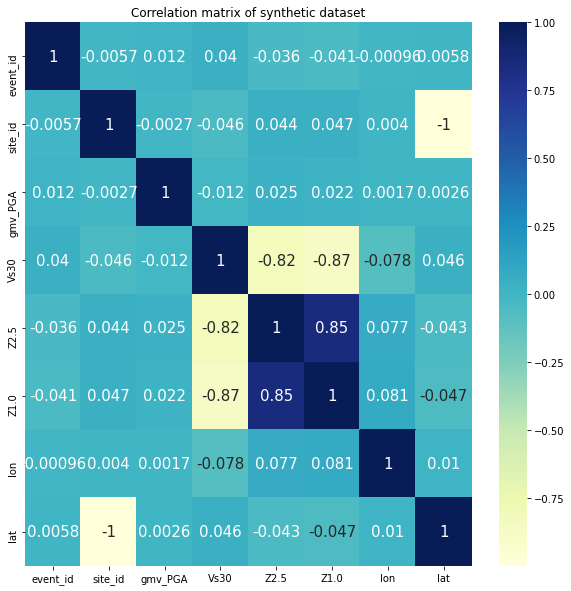

In [ ]:
# Checking correlation
corr_heatmap(ctgan_df, 'synthetic dataset')

As we could see, the CTGAN model seemed to learn well the features in the sub-dataset. In particular, this synthetic data could show:
- Strong negative correlation between site_id and lat
- Strong negative correlation between Vs30 and Z2.5
- Strong negative correlation between Vs30 and Z1.0
- Strong positive correlation between Z2.5 and Z1.0

### 5.2.2. Variances

In [ ]:
# Checking variances
ctgan_df_nolonlat.var()

event_id     69852.456058
site_id     499954.068459
gmv_PGA          0.000082
Vs30        106419.116658
Z2.5             1.189234
Z1.0         22345.812858
dtype: float64

The CTGAN model seemed to catch the similar variances shown in the subset data. In particular,
- Variables event_id, site_id, Vs30, Z1.0 have very high variances
- Variables PGA, Z2.5, lon, lat have very low variances, especially PGA was close to 0.

### 5.2.3. Distributions

Text(0.5, 0.98, 'Distribution of variables in synthetic dataset')

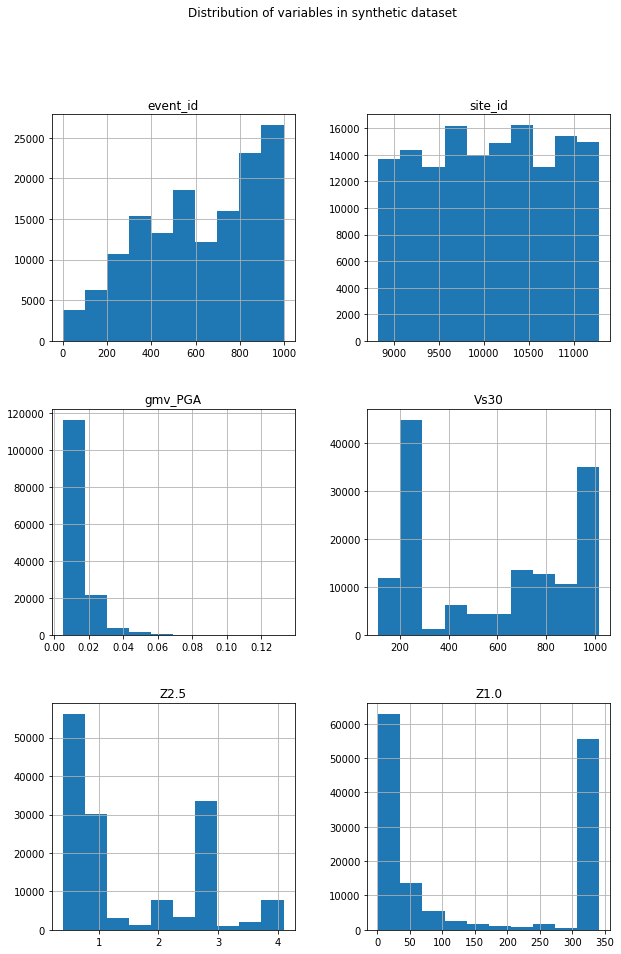

In [ ]:
# Checking distributions
ctgan_df_nolonlat.hist(figsize=(10, 15))
plt.suptitle('Distribution of variables in synthetic dataset')

The CTGAN model seemed to learn very well the distributions of the variables. It could learn approximately the similar boundaries about maximum and minimum of variables. However, there was still some small differences. In particular, PGA and Vs30 seemed to have more frequencies than the sub-dataset.

### 5.2.4. Other statistical summary

In [ ]:
# Checking the descriptive summary
ctgan_df_nolonlat.describe()

,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0
count,145756.000000,145756.000000,145756.000000,145756.000000,145756.000000,145756.000000
mean,619.155939,10073.050571,0.015306,575.922746,1.466756,151.614623
std,264.296152,707.074302,0.009058,326.219430,1.090520,149.485159
min,2.000000,8827.000000,0.005014,112.642875,0.399223,1.421507
25%,402.000000,9479.000000,0.010616,212.323050,0.473228,10.005165
50%,626.000000,10100.000000,0.012219,603.649620,0.876071,64.061889
75%,851.000000,10693.000000,0.016560,918.652104,2.636870,333.868330
max,996.000000,11280.000000,0.133082,1015.790346,4.099280,341.122643


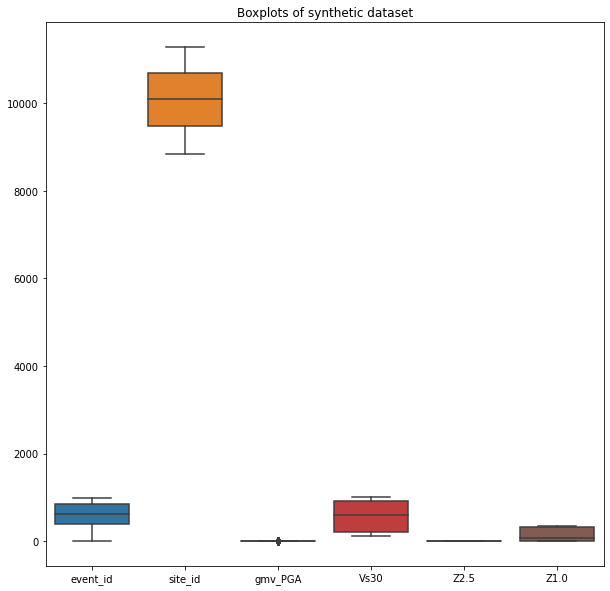

In [ ]:
# Checking boxplots
full_boxplots(ctgan_df_nolonlat, 5, 'synthetic dataset')

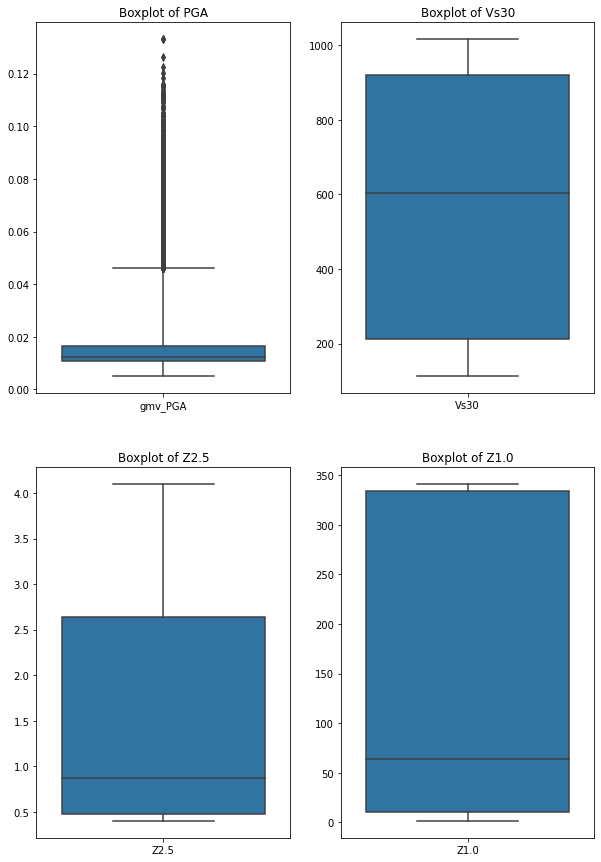

In [ ]:
# Checking boxplots of PGA, Vs30, Z2.5, and Z1.0
each_boxplot(ctgan_df_nolonlat, 5, 'n')

Through the results above, we could see a small differences in the boudaries about the maximum and minimum of variables clearer (Vs30, for example). However, they were still highly similar to the sub-dataset.

In the next section, we would build up the evalution on the similarity on the values of the sub-dataset and the synthetic data. Through this way, we could assess more correctly if the synthetic data contained the underlying features/ insights of the sub-dataset.

# **6. EVALUATIONS**

There are several ways mentioned publicly to evaluate the similarity of datasets. Some of them were just mentioned as a theory, some of them were developed into lines of codes. Among the methods built up as codes, most of them were used to evaluate the similarity column-by-column among datasets. Just a very few of them were used to evaluate the similarity of the whole datasets, in which the relationships of all columns were included. In this project, we tried numerous methods which were introduced publicly and ended up with selecting some of the most suitable ones combining with building up our own approach maybe for only this type of datasets. The trial and chosen methods would be explained as below:

- To evaluate the similarity between two whole datasets, we applied the metrics from evaluation sdv package version 0.6.1 (please see [here](https://sdv.dev/SDV/user_guides/evaluation/single_table_metrics.html) for more information). This package included 4 methods which were used as 4 metric families.
  + Statistical metrics: These measures mostly fit well on datasets including many categorial, boolean and discrete variables. Hence, we did not choose this.
  + Likelihood metrics: These measures could not handle well dataset having common problems such as missing values, outliers, and correlations. Also, the results of these metrics were not easy to understand. Therefore, we did not select this method.
  + Machine learning efficacy metrics: These measures could only fit the common predictive data science problem, in which there would be one column used as target column to predict. Hence, we did not choose these methods either.
  + **Detection metrics**: These measures would fit well on any type of variables and any type of datasets. In this family, Logistic Detection was CHOSEN to evaluate the similarity of two datasets in this project. To explain about this method, it would shuffle the subset data and synthetic data, create one more column with labels synthetic and real data, and put all of them into one dataset. The cross-validation with Logistic Regression from scikit-learn would be used to predict these labels. The output of the metrics would be the result of 1 minus the average ROC AUC score across all the cross validation splits. The result should be closer to 1 as high similarity. Please see [here](https://github.com/sdv-dev/SDV/issues/287) for more details.

Next, we could use this Logistic Detection to evaluate the similarity of column-by-column and the relationships. However, we decided not to go further with this method. To explain, this method was so new (published on 31-12-2020) which had not been tested before, so a large improvement on this sdv package would be highly required. Also, there were still some errors which had not been solved yet. Therefore, to know which column was high and low similar, or which relationships that ctgan model could learn, we decided to utilise several the methods well-known widely to build up our own evaluation methods for this type of dataset specifically. Please see [here](https://towardsdatascience.com/calculate-similarity-the-most-relevant-metrics-in-a-nutshell-9a43564f533e) for information about the codes that we used. In particular,

- Cosine Similarity method: We would use this method for all variables to evaluate the similarity through individual column (column-by-column).To explain, this method did not require the values being sorted before the calculation. (please see [here](https://towardsdatascience.com/calculate-similarity-the-most-relevant-metrics-in-a-nutshell-9a43564f533e) for more information).

- Correlation method: We would also use this method for all variables but in different ways for discrete variables and continuous variables.
  + For two discrete columns site_id and event_id, we would count the frequencies of each site_id and each event_id in both sub-dataset and synthetic dataset. Following this, we would merge them by site_id and event_id to do the computation and plotting. Through this way, we could see clearer the learning results of ctgan model on these variables.
    + As to site_id, the result showed the extremely high similarity. Also, this was the geometric variable for doing the maps, thus we decided to use site_id as the key variable for futher similarity measures of the relationships between it and PGA, Vs30, Z2.5, and Z1.0.
  
    + As to event_id, this was not the important variable (as GNS team said), we would not evaluate similarity on further relationship between this and site_id.

  + For the group of continuous variables - PGA, Vs30, Z2.5, and Z1.0, as to the relationships of these variables with site_id, since for one site_id there would be many PGA, Vs30, Z2.5, and Z1.0 values, we decided to average all these values for each site_id. Although the accuracy in evaluating the similarity would be reduced at some level due to losing some values, the correlation and mapping were still enough to evaluate the similarity on the relationships and even on column-by-column. To process, we would sort and merge variable-by-variable from both datasets by the site_id. After that, we calculated and plot Correlations to evaluate the similarity.

- Mapping method: we would use mapping to see if the patterns in the sub-dataset could be learnt by the ctgan model. Following this, there would be three types of maps for each variable. The first map would use only the average values. However, these values could show very vaguely the underlying features of variables due to very high or very low variances. Hence, we decided to use scale functions on each variable to make the patterns clearer to observe. We would use two types of scaler - MinMax Scaler and Quantile Scaler. The result of MinMax Scaler was almost similar to most of the other scalers listed [here](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_all_scaling.html), thus it would be a good representative for most of them. The Quantile Scaler was chosen due to the difference in the outcome from other scalers. In fact, the Quantile Scaler shown clearer patterns.

In general, the process of evaluating would be described in a diagram as below:

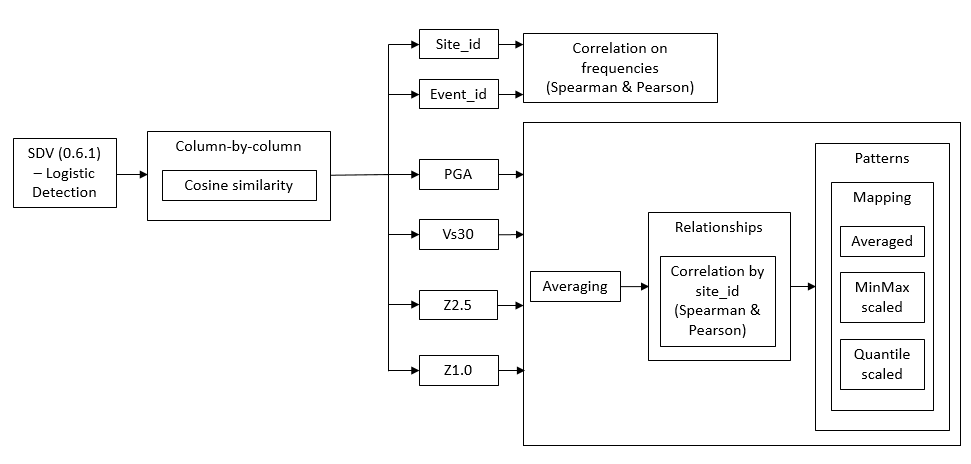

## 6.1. Evaluation on whole dataset

At first, we would install the sdv package version 0.6.1 by running the code box below. This code box should be run only once and should be run after installing ctgan package version 0.2.2. After that, it should be COMMENTED immediately.

In [ ]:
# Installing sdv version 0.6.1
# !pip install sdv==0.6.1
# from sdv.evaluation import evaluate

     |████████████████████████████████| 81kB 8.5MB/s 
     |████████████████████████████████| 9.5MB 30.6MB/s 
     |████████████████████████████████| 51kB 9.0MB/s 
     |████████████████████████████████| 81kB 13.2MB/s 
     |████████████████████████████████| 12.4MB 51.5MB/s 
     |████████████████████████████████| 12.6MB 265kB/s 
     |████████████████████████████████| 225kB 63.5MB/s 
     |████████████████████████████████| 5.6MB 17.1MB/s 
     |████████████████████████████████| 92kB 13.5MB/s 
     |████████████████████████████████| 9.5MB 19.6MB/s 
     |████████████████████████████████| 675kB 58.5MB/s 
     |████████████████████████████████| 102kB 14.9MB/s 
     |████████████████████████████████| 102kB 16.0MB/s 
  Created wheel for xeger: filename=xeger-0.3.5-cp36-none-any.whl size=4743 sha256=be8059c93042163f869a5b96a34d292d263f6ee83e679cbebf0e3c8698a691eb
  Stored in directory: /root/.cache/pip/wheels/4c/f6/28/ee8242f69d847db648cd634839f5088540df91d5e8f5d267b4
  Created wheel for co

ImportError: ignored

After installing the sdv version 0.6.1, the code box might get error as the available results above. However, it should be ignored and let the later codes run. (The error was because of some package error which would need improving from the authors)

In [ ]:
# Importing evaluate function one more time as the first time was not successful
from sdv.evaluation import evaluate

In [ ]:
# Evaluating two whole datasets by Logistic Detection
# Both subset and synthetic datasets were used without longitude and latitude
# as these variables were not used in ctgan model
%%time

evaluate(ctgan_df_nolonlat, 
         HawkesBay_data_droplonlat, 
         metrics=['LogisticDetection'], 
         aggregate=False)

CPU times: user 2.03 s, sys: 1.24 s, total: 3.27 s
Wall time: 1.8 s


,metric,name,score,min_value,max_value,goal
0,LogisticDetection,LogisticRegression Detection,0.54165,0.0,1.0,MAXIMIZE


As we can see, the result was over 0.5 which could be seen that the synthetic data was relatively similar to the subset data. In the next section, we would check to see which variables were learnt well by the ctgan model, which ones could not be learnt well. However, before processing further, two copies of both the sub-dataset and the synthetic data would be created for separately manipulating without any impacts to the original ones. These copies would be used mostly for column-by-column evaluations.

In [ ]:
# Creating copies for both subset and synthetic data to evaluate specifically for site_id only
real_copy = HawkesBay_data.copy(deep=True)
ctgan_copy = ctgan_df.copy(deep=True)

Next, we started to do the column-by-column evaluations by Cosine Similarity for all variables.

## 6.2. Evaluations on all variables by Cosine Similarity method

The Cosine Similarity would used from the scikit-learn package. To use this function, the two columns should be transfered into array types. After that, we needed to reshape the arrays as Cosine Similarity in scikit-learn would not allow 1 dimension array. We combined all these steps into one function to run and see the results more easily and conveniently.

In [ ]:
# Creating function to do cosine similarity calculation
# This function would be used for site_id and event_id

def calculate_cosine_similarity(column_calculated):
  ''' This function is to calculate cosine similarity of two variables
  Sources: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html#sklearn.metrics.pairwise.cosine_similarity
           https://gist.github.com/pgolding/fdf74a3e8e797fad0391befd5a906ddb
  Arguments:
            column_calculated:
                      The name of the column/variable need calculating cosine similarity.
  '''                    

  # Creating dataframes for both subset and synthetic data 
  # Each dataframe contains only one column
  real_dataframe = pd.DataFrame({column_calculated: real_copy[column_calculated]})
  ctgan_dataframe = pd.DataFrame({column_calculated: ctgan_copy[column_calculated]})

  # Converting into numpy array
  real_array = real_dataframe.to_numpy()
  ctgan_array = ctgan_dataframe.to_numpy()

  # Reshaping arrays
  real_array = real_array.reshape(1, -1)
  ctgan_array = ctgan_array.reshape(1, -1)

  # Calculating cosine similarity
  from sklearn.metrics.pairwise import cosine_similarity
  result = cosine_similarity(real_array, ctgan_array)
  return result

In [ ]:
# Evaluating similarity of variables
# Creating variables containing all columns' names
var_name = real_copy.drop(columns=['lon', 'lat']).columns.to_list()

# Calculating cosine similarity
for name in var_name:
  result = calculate_cosine_similarity(name)[0][0]
  print('Cosine similarity score of {} is: {:.5f}'.format(name, result))

Cosine similarity score of event_id is: 0.84644
Cosine similarity score of site_id is: 0.99512
Cosine similarity score of gmv_PGA is: 0.67116
Cosine similarity score of Vs30 is: 0.75188
Cosine similarity score of Z2.5 is: 0.65383
Cosine similarity score of Z1.0 is: 0.52338


As we noticed from the results, all the variables had the Cosine Similarity score over 0.5. This could be seen as a good learning from the CTGAN model. However, PGA, Z2.5 and Z1.0 had the results very close to 0.5 and much lower than other outcomes. Site_id had the highest score. This was also the reason (as we explained before) to choose this variable as the key variable. Nevertheless, evaluating similarity on column-by-column did not include checking of the neccesary relationships like the site_id with all other continuous variables (as mentioned before). Hence, the Correlation method would be processed in the next section, yet not only for checking relationships, but also for checking frequencies of discrete variables.

## 6.3. Evaluations on all variables by Correlation method

At first, we created two functions to calculate and plot the correlation for each variable.
- Function1: To give the results of Pearson's and Spearman's correlations
- Function2: To plot the correlations

At first, we need to reinstall the matplotlib and seaborn to the newest versions to use all facilities as below. To explain, the installing of ctgan version 0.2.2 and sdv version 0.6.1 might degrade the versions of these packages into the older ones.

In [ ]:
# Although matplotlib and seaborn were installed, we still install them again with newer versions
!pip install matplotlib
!pip install seaborn==0.11.1

     |████████████████████████████████| 286kB 18.4MB/s 
ERROR: sdmetrics 0.1.1 has requirement seaborn<0.11,>=0.9, but you'll have seaborn 0.11.1 which is incompatible.
  Found existing installation: seaborn 0.10.1
    Uninstalling seaborn-0.10.1:
      Successfully uninstalled seaborn-0.10.1


To calculate the correlations by Pearson or Spearman styles, we would use the functions from scipy.stats package. The dataset we used would be merged with outer style:
+ For discrete variables: count-by-count by site_id or by event_id
+ For continuous variables: variable-by-variable by site_id

By doing this way, there might be some null values. To explain, there would be some unmatched event_id or site_id values from real and ctgan data. To sort this problem out, we would replace the null values with 0. All of these steps would be combined into one function (Function 1) to produce correlations by both Pearson and Spearman styles.

In [ ]:
# Function 1
# Creating a function to calculate Pearson's and Spearman's correlations
# This function would be used for all correlation calculation in this project

%matplotlib inline
plt.style.use('seaborn-whitegrid')
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

def calculate_correlation(real_df, 
                          ctgan_df, 
                          column_merge, 
                          column_correlated,
                          newname_column_correlated):
  ''' The function is used to calculate the correlation similarity - both Pearson and Spearman style
  For more details please visit: https://towardsdatascience.com/calculate-similarity-the-most-relevant-metrics-in-a-nutshell-9a43564f533e
  Arguments:
            real_df:
                Dataframe created from subset data.
            ctgan_df:
                Dataframe created from synthetic data.
            column_merge:
                Column in both dataframes used to merge.
            column_correlated:
                Current name of columns would be used to calculate correlations.
            newname_column_correlated:
                New name for columns used to calculate correlations.
  '''

  # Preparing data
  dfCorrelation = real_df
  dfCorrelation.rename(columns={column_correlated:f'HawkesBay_real_{newname_column_correlated}'}, inplace=True)
  dfCorrelation = pd.merge(dfCorrelation, ctgan_df, how='outer', on=column_merge)
  dfCorrelation.rename(columns={column_correlated:f'HawkesBay_ctgan_{newname_column_correlated}'}, inplace=True)
  dfCorrelation = dfCorrelation.fillna(0)

  # Calculating Pearson's correlation
  corrp, _ = stats.pearsonr(dfCorrelation[f'HawkesBay_real_{newname_column_correlated}'].values, 
                            dfCorrelation[f'HawkesBay_ctgan_{newname_column_correlated}'].values)

  # Calculating Spearman's correlation
  corrs, _ = stats.spearmanr(dfCorrelation[f'HawkesBay_real_{newname_column_correlated}'].values, 
                             dfCorrelation[f'HawkesBay_ctgan_{newname_column_correlated}'].values)

  return corrp, corrs

The function 2 would be the same as the function 1 to produce the plot. Nevertheless, we would not use the results from function 1 to use into function 2, as we would produce and use some hidden variables during the calculation. In lieu of it, we would reproduce the same code with more developing to produce the plots with figures clearly.

In [ ]:
# Function 2
# Creating a function to plot the correlations of both styles - Pearson and Spearman
# This function would be used for all correlation calculation in this project

%matplotlib inline
plt.style.use('seaborn-whitegrid')
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

def plot_correlation(real_df, 
                     ctgan_df, 
                     column_merge,
                     column_correlated,
                     newname_column_correlated):
  ''' The function is used to plot the correlation similarity - both Pearson and Spearman styles
  For more details please visit: https://towardsdatascience.com/calculate-similarity-the-most-relevant-metrics-in-a-nutshell-9a43564f533e
  Arguments:
            real_df:
                Dataframe created from subset data.
            ctgan_df:
                Dataframe created from synthetic data.
            column_merge:
                Column in both dataframes used to merge.
            column_correlated:
                Current name of columns would be used to calculate correlations.
            newname_column_correlated:
                New name for columns used to calculate correlations.
  '''

  # Preparing data
  dfCorrelation = real_df
  dfCorrelation.rename(columns={column_correlated:f'HawkesBay_real_{newname_column_correlated}'}, inplace=True)
  dfCorrelation = pd.merge(dfCorrelation, ctgan_df, how='outer', on=column_merge)
  dfCorrelation.rename(columns={column_correlated:f'HawkesBay_ctgan_{newname_column_correlated}'}, inplace=True)
  dfCorrelation = dfCorrelation.fillna(0)

  # Calculating Pearson's correlation
  corrp, _ = stats.pearsonr(dfCorrelation[f'HawkesBay_real_{newname_column_correlated}'].values, 
                            dfCorrelation[f'HawkesBay_ctgan_{newname_column_correlated}'].values)
  print("Pearson's correlation: %.3f" % corrp)

  # Calculating Spearman's correlation
  corrs, _ = stats.spearmanr(dfCorrelation[f'HawkesBay_real_{newname_column_correlated}'].values, 
                             dfCorrelation[f'HawkesBay_ctgan_{newname_column_correlated}'].values)
  print("Spearman's correlation: %.3f" % corrs)

  # Plotting
  plt.style.use('seaborn-whitegrid')
  fig, ax = plt.subplots(figsize=(10, 10))
  pl = sns.regplot(x=f'HawkesBay_ctgan_{newname_column_correlated}', 
                   y=f'HawkesBay_real_{newname_column_correlated}', 
                   data=dfCorrelation, fit_reg=True, 
                   color='black', marker='+', ax=ax)
  pl.set_title(f"Correlation of {newname_column_correlated}")
  plt.show()

After creating neccesary functions, we would apply them into the discrete and continuous variables as below.

### 6.3.1. Evaluations on frequencies of discrete variables by Correlation method

As to discrete variables, at first, we separate the variables into discrete and continuous for easy processing. After that, we would create a function to count the frequencies of them in the datasets.

In [ ]:
# Creating a list of discrete variables
discrete_var = var_name[:2][::-1]

# Creating a list of continuous variables
continuous_var = var_name[2:]

In [ ]:
# Creating a function to count the frequency of each unique site_id/event_id
def count_fid_occurences(df, column):
  '''The function is used to count the frequency of a given column from a dataframe
  Arguments:
            df:
              Dataframe contains the column.
            column:
              The column needs counting.
  '''
  count = df[column].value_counts()
  count_df = pd.DataFrame({column: count.index, 'count': count.values})
  count_df["count"] = pd.to_numeric(count_df["count"])
  return count_df

In [ ]:
# Checking the number of rows by site_id after counting the frequency
# To see if the ctgan model could learn the quantity of unique site_id.
# If the result equals to 0, the model learnt well
len(count_fid_occurences(real_copy, 'site_id')) - len(count_fid_occurences(ctgan_copy, 'site_id'))

0

In [ ]:
# Checking the number of rows by event_id after counting the frequency
# To see if the ctgan model could learn the quantity of unique event_id.
# If the result equals to 0, the model learnt well
len(count_fid_occurences(real_copy, 'event_id')) - len(count_fid_occurences(ctgan_copy, 'event_id'))

51

As the result, the ctgan model learnt the quantity of unique values of the site_id better than of the event_id. Next, we would combine the functions to calculate and plot correlations, function to count the frequency, and function to create a dataframe for only two variables (site_id with one continuous variable - this function would be created later) together into two functions as below.
- Function to calculate the correlation for a list of discrete or continuous variables and produce a table of results
- Function to plot the correlation for a list of discrete or continuous variables

In [ ]:
# Creating a function to create a table of correlations for variables
# This function would be used for all correlations in this project 

def corr_df(list_variable_name, type_var):
  ''' This function is to create a dataframe showing Pearson's and Spearman's correlations
      for all variables
  For more details please visit: https://datatofish.com/create-pandas-dataframe/
  Arguments:
            list_variable_name:
                List of names of selected variables in a datasets
            type_var:
                Type of variables - discrete or continuous (d or c)
  '''
  # Creating two lists containing correlations scores for variables
  p_result = []
  s_result = []

  # Calculating correlations for discrete variables
  if type_var == 'd':
    for var in list_variable_name:
      corr_p, corr_s = calculate_correlation(count_fid_occurences(real_copy, var),
                                             count_fid_occurences(ctgan_copy, var),
                                             var, 'count', 'correlation')
      p_result.append(corr_p)
      s_result.append(corr_s)
  # Calculating correlations for continuous variables
  else:
    for var in list_variable_name:
      corr_p, corr_s = calculate_correlation(continuous_var_df(real_mean, var),   # This function would be created later
                                             continuous_var_df(ctgan_mean, var),  # This function would be created later
                                             'site_id', var, 'averaged_'+var)
      p_result.append(corr_p)
      s_result.append(corr_s)

  # Creating a table of correlations for variables
  corr_dict = {'Variables': list_variable_name,
               "Pearson's Correlation": p_result,
               "Spearman's Correlation": s_result}

  corr_df = pd.DataFrame(corr_dict,
                         columns=['Variables', 
                                  "Pearson's Correlation",
                                  "Spearman's Correlation"])

  return corr_df

In [ ]:
# Creating a table of correlations of discrete variables
corr_df(discrete_var, 'd')

,Variables,Pearson's Correlation,Spearman's Correlation
0,site_id,0.732485,0.741475
1,event_id,0.976484,0.982675


In [ ]:
# Creating a function to call out plots of correlations of variables
# This function would be used for all of correlation plotting in this project

def corr_plot(list_variable_name, type_var):
  ''' This function is to create a dataframe showing Pearson's and Spearman's correlations
      for all variables
  Arguments:
            list_variable_name:
                List of names of selected variables in a datasets
            type_var:
                Type of variables - discrete or continuous (d or c)
  '''
  # Plotting for discrete variables
  if type_var == 'd':
    for var in list_variable_name:
      print()
      print("-"*35 + " " + var + " " + "-"*35)
      plot_correlation(count_fid_occurences(real_copy, var),
                       count_fid_occurences(ctgan_copy, var),
                       var, 'count', var+'_count')
  # Plotting for continuous variables
  else:
    for var in list_variable_name:
      print()
      print("-"*35 + " " + var + " " + "-"*35)
      plot_correlation(continuous_var_df(real_mean, var),   # This function would be created later
                       continuous_var_df(ctgan_mean, var),  # This function would be created later
                       'site_id', var, 'averaged_'+var)
    


----------------------------------- site_id -----------------------------------
Pearson's correlation: 0.732
Spearman's correlation: 0.741


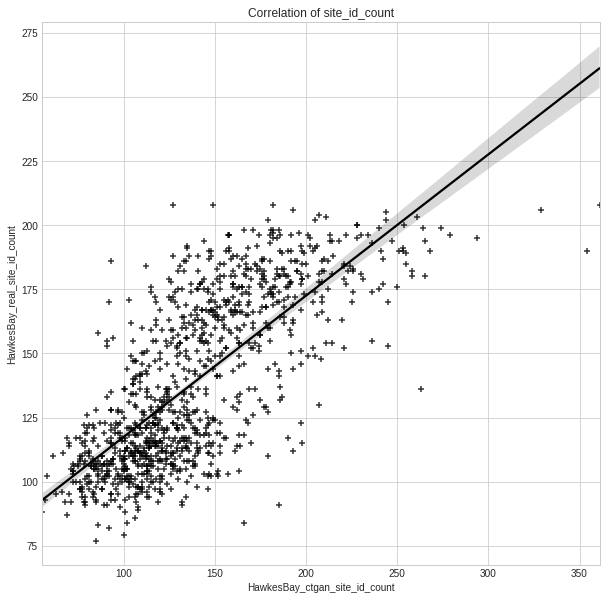


----------------------------------- event_id -----------------------------------
Pearson's correlation: 0.976
Spearman's correlation: 0.983


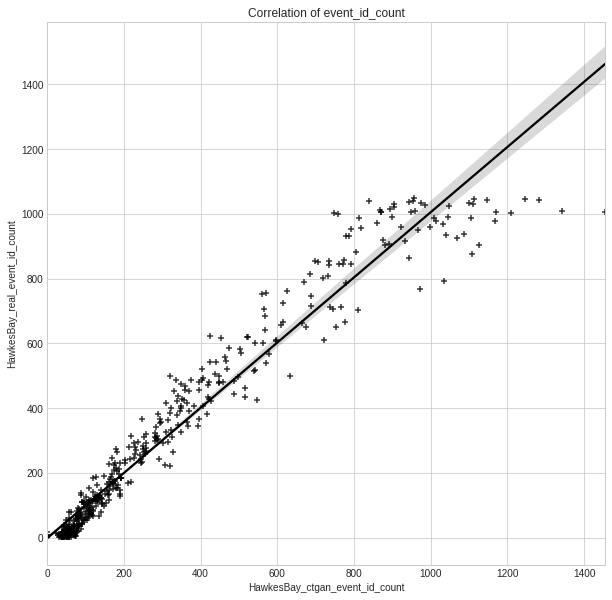

In [ ]:
# Plotting correlations for discrete variables
corr_plot(discrete_var, 'd')

As we could see the results, both of the variables had very high Correlation scores for both Spearman and Pearson styles. The result of event_id was higher than site_id. However, we would still use site_id as the key variable for further process. To explain, it had more equal unique values than event_id, which would help much in the length of values when we did the averaging data. Additionally, it was the ID for geometrical points of longitude and latitude which would help us much when doing the mapping with averaging data. In the next section, we would perform the Correlation method on continuous variables.

### 6.3.2. Evaluations on values of continuous variables by Correlation method

To process the Correlation method for continuous data in this project, at first, the data would be averaged by site_id. To explain for this process, there would be many values of PGA, Vs30, Z2.5, and Z1.0 for just one site_id.

In [ ]:
# Creating a function to create an averaged dataset
def averaged_dataset(df):
  ''' This function is to average dataframe containing longitude and latitude, 
      specifically real data and ctgan data in this project
  Arguments:
            df:
              Dataframe needs averaging
  '''
  # Averaging dataset without longitude and latitude
  df_mean = df.drop(columns=['lon', 'lat']).groupby('site_id').mean()

  # Merging with sitemesh_133.csv file to get longitude and latitude
  df_mean_lonlat = pd.merge(df_mean, geometrical_data, on='site_id')

  return df_mean_lonlat

In [ ]:
# Applying averaging function to both real and ctgan dataframes
real_mean = averaged_dataset(real_copy)
ctgan_mean = averaged_dataset(ctgan_copy)

In [ ]:
# Checking data information
real_mean.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1050 entries, 0 to 1049
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   site_id   1050 non-null   int64  
 1   event_id  1050 non-null   float64
 2   gmv_PGA   1050 non-null   float64
 3   Vs30      1050 non-null   float64
 4   Z2.5      1050 non-null   float64
 5   Z1.0      1050 non-null   float64
 6   lon       1050 non-null   float64
 7   lat       1050 non-null   float64
dtypes: float64(7), int64(1)
memory usage: 73.8 KB


In [ ]:
# Checking data information
ctgan_mean.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1050 entries, 0 to 1049
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   site_id   1050 non-null   int64  
 1   event_id  1050 non-null   float64
 2   gmv_PGA   1050 non-null   float64
 3   Vs30      1050 non-null   float64
 4   Z2.5      1050 non-null   float64
 5   Z1.0      1050 non-null   float64
 6   lon       1050 non-null   float64
 7   lat       1050 non-null   float64
dtypes: float64(7), int64(1)
memory usage: 73.8 KB


As the results, both real and ctgan data after averaging had the same number of observations. This meant that ctgan model could learn the quantity of unique observations of discrete variables well. However, the values of them might be different, which might lead to different values of continuous variables. Hence, we still needed to process further. Next, we would create a function to create a small dataframe including only two columns - site_id and a continuous variable. After that, we would calculate and plot the correlations.

In [ ]:
# Creating a function to create a small dataframe including a continuous variable and site_id
def continuous_var_df(df, column):
  '''This function is to create a small dataframe including two columns - 
     site_id and a continuous variable
  Arguments:
            df:
              Dataframe contains the site_id and the continuous variable
            column:
              Column's name
  '''
  con_var_df = pd.DataFrame({'site_id': df.site_id,
                             column: df[column]})
  return con_var_df


----------------------------------- gmv_PGA -----------------------------------
Pearson's correlation: 0.014
Spearman's correlation: 0.025


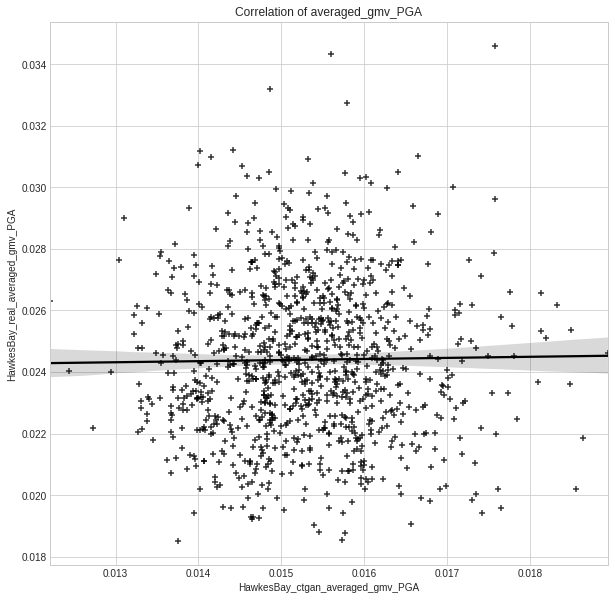


----------------------------------- Vs30 -----------------------------------
Pearson's correlation: 0.719
Spearman's correlation: 0.704


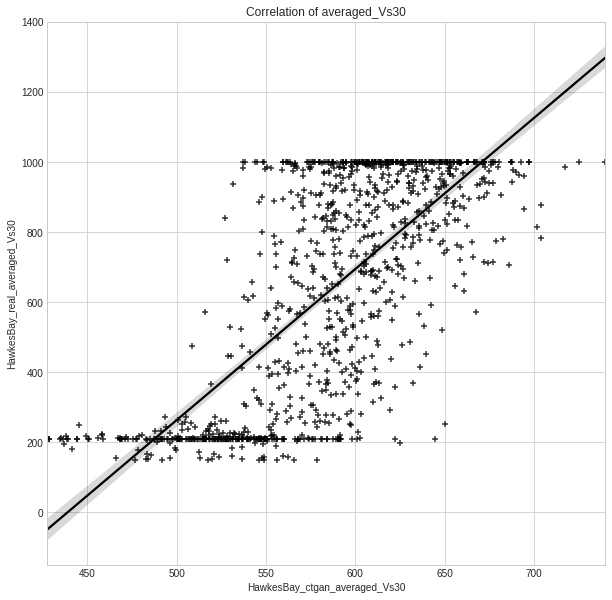


----------------------------------- Z2.5 -----------------------------------
Pearson's correlation: 0.732
Spearman's correlation: 0.657


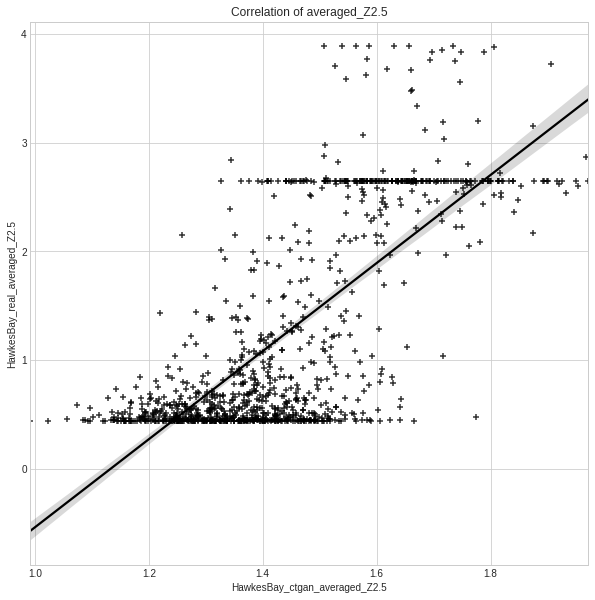


----------------------------------- Z1.0 -----------------------------------
Pearson's correlation: 0.725
Spearman's correlation: 0.669


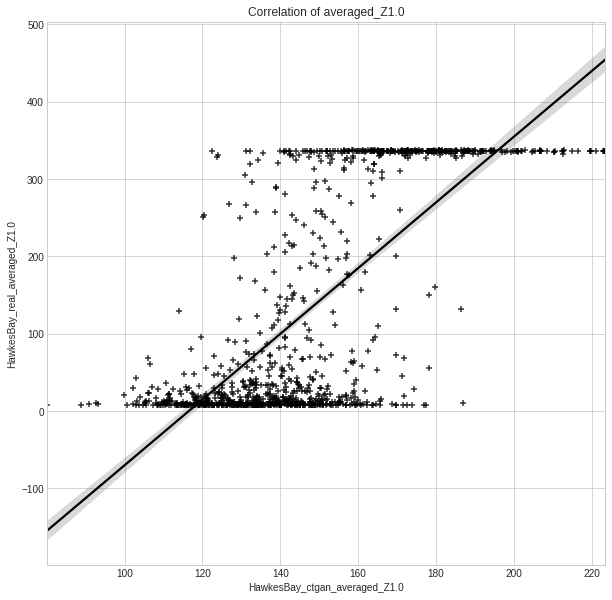

In [ ]:
# Plotting correlations for continuous data
corr_plot(continuous_var, 'c')

In [ ]:
# Creating a table of correlations of continuous variables
corr_df(continuous_var, 'c')

,Variables,Pearson's Correlation,Spearman's Correlation
0,gmv_PGA,0.013885,0.025232
1,Vs30,0.718894,0.704250
2,Z2.5,0.732090,0.656602
3,Z1.0,0.724869,0.669427


As the results, we could see that except PGA had very low result, all other variables had high correlation scores. To explain, this might be because of near-zero-variance or due to outliers coming from the values close to 0 of PGA.

## 6.4. Evaluations on patterns of continuous variables by Mapping method

Due to the size and the quantity of graphs and maps, this section would be separated into the private part for each continuous variable. Each section would includes two type of figures - distributions and maps. In particular,
- Distributions: We would process the real and ctgan data distributions on specific variable when averaging, MinMax scaling, and Quantile scaling.
- Maps: We would process the real and ctgan data maps on specific variable when averaging, MinMax scaling, and Quantile scaling.

To process efficiently, at first, the data would be transfered to geopandas datafame format for mapping. Also, the MinMax and Quantile scalings also needed implementing for a specific variable. All of these steps would be combined into one function as below.

In [ ]:
# Installing geopandas
!pip install geopandas

     |████████████████████████████████| 972kB 22.1MB/s 
     |████████████████████████████████| 6.5MB 56.4MB/s 
     |████████████████████████████████| 14.8MB 225kB/s 


In [ ]:
# Creating a function to convert the pandas dataframes 
# into geopandas dataframe for mapping. This function also does
# MinMax and Quantile scaling for a specific variable

# Importing preprocessing from scikit-learn for using scaling functions
from sklearn import preprocessing

# Importing geopandas
import geopandas as gpd

def gdf_minmax_quantile(variable):
  '''This function is to convert the pandas dataframes into geopandas dataframes for mapping.
     It also includes doing scaling with MinMax and Quantile styles for a specific variable.
  For more details please visit: https://geopandas.org/gallery/create_geopandas_from_pandas.html
                                 https://stackoverflow.com/questions/63644131/how-to-use-geopandas-to-plot-latitude-and-longitude-on-a-more-detailed-map-with
  Arguments:
            variable:
                The variable needs mapping
  '''
  # Creating two more copies from the real and ctgan dataframes
  # to avoid the impacts from the further process
  real_mean_copy = real_mean.copy(deep=True)
  ctgan_mean_copy = ctgan_mean.copy(deep=True)

  # Converting pandas dataframes into geopandas dataframes
  gdf_real = gpd.GeoDataFrame(real_mean_copy,
                              geometry = gpd.points_from_xy(real_mean_copy.lon, 
                                                           real_mean_copy.lat))
  gdf_ctgan = gpd.GeoDataFrame(ctgan_mean_copy,
                               geometry = gpd.points_from_xy(ctgan_mean_copy.lon, 
                                                           ctgan_mean_copy.lat))
  
  # Scaling data
  # Calling out scaling functions
  min_max_scaler = preprocessing.MinMaxScaler()
  quantile_scaler = preprocessing.QuantileTransformer()

  # MinMax scaling
  gdf_real['MinMax'] = min_max_scaler.fit_transform(gdf_real[[variable]].values.astype(float))
  gdf_ctgan['MinMax'] = min_max_scaler.fit_transform(gdf_ctgan[[variable]].values.astype(float))
  
  # Quantile scaling
  gdf_real['Quantile'] = quantile_scaler.fit_transform(gdf_real[[variable]].values.astype(float))
  gdf_ctgan['Quantile'] = quantile_scaler.fit_transform(gdf_ctgan[[variable]].values.astype(float))

  return gdf_real, gdf_ctgan

Next, we would create a function to plot the real and ctgan data distributions for a specific continuous variable when averaging, MinMax scaling and Quantile scaling.

In [ ]:
# Creating a function to plot the distributions of the pair - real and ctgan data 
# for averaged, MinMax scaling, Quantile scaling versions

def dis_plot(variable):
  '''This function is to plot the real data and ctgan data distributions
     when averaging, MinMax scaling, and Quantile scaling
  For more details please visit: https://dev.to/thalesbruno/subplotting-with-matplotlib-and-seaborn-5ei8
  Arguments:
          variable:
              The variable needs mapping
  '''
  fig, axes = plt.subplots(2, 3, figsize=(20, 15))
  fig.suptitle(f'Distributions of {variable} of real and ctgan data when averaging, MinMax scaling, and Quantile scaling')

  # Converting pandas dataframes into geopandas dataframes
  # and scaling
  gdf_real_var, gdf_ctgan_var = gdf_minmax_quantile(variable)

  # Real data - Distributions when averaging, MinMax scaling, and Quantile scaling
  sns.distplot(gdf_real_var[variable], kde=True, ax=axes[0, 0]).set_title('Real data distributions - Average')
  sns.distplot(gdf_real_var.MinMax, kde=True, ax=axes[0, 1]).set_title('Real data distributions - MinMax Scaling')
  sns.distplot(gdf_real_var.Quantile, kde=True, ax=axes[0, 2]).set_title('Real data distributions - Quantile Scaling')

  # Ctgan data - Distributions when averaging, MinMax scaling, and Quantile scaling
  sns.distplot(gdf_ctgan_var[variable], kde=True, color='y', ax=axes[1, 0]).set_title('Ctgan data distributions - Average')
  sns.distplot(gdf_ctgan_var.MinMax, kde=True, color='y', ax=axes[1, 1]).set_title('Ctgan distributions - MinMax Scaling')
  sns.distplot(gdf_ctgan_var.Quantile, kde=True, color='y', ax=axes[1, 2]).set_title('Ctgan data distributions - Quantile Scaling')

After that, another function was created to do the mapping.

In [ ]:
# Creating a function to map the underlying features of continuous data based on the site_id

# Importing wrap function
from textwrap import wrap

def mapping(variable):
  '''This function is to map the patterns in the real data and ctgan data
     when averaging, MinMax scaling, and Quantile scaling
  For more details please visit: https://dev.to/thalesbruno/subplotting-with-matplotlib-and-seaborn-5ei8
  Arguments:
          variable:
              The variable needs mapping
  '''
  plt.style.use('seaborn-darkgrid')
  fig, ((ax1, ax2), (ax1b, ax2b), (ax1c, ax2c)) = plt.subplots(nrows=3, ncols=2, 
                                                               figsize=(15, 15))
  # Converting pandas dataframes into geopandas dataframes
  # and scaling
  gdf_real_var, gdf_ctgan_var = gdf_minmax_quantile(variable)

  # Averaging
  gdf_real_var.plot(ax=ax1, column=variable, cmap='YlOrRd', legend=True)
  gdf_ctgan_var.plot(ax=ax2, column=variable, cmap='YlOrRd', legend=True)
  ax1.set_title("\n".join(wrap('Averaged - Shaking events in Hawkes Bay - Real data ~ 1 millions observations', 35)))
  ax1.ticklabel_format(useOffset=False, style='plain')
  ax2.set_title("\n".join(wrap('Averaged - Shaking events in Hawkes Bay - CTGAN data ~ 20% observations training set', 35)))
  ax2.ticklabel_format(useOffset=False, style='plain')

  # MinMax scaling 
  gdf_real_var.plot(ax=ax1b, column='MinMax', cmap='YlOrRd', legend=True)
  gdf_ctgan_var.plot(ax=ax2b, column='MinMax', cmap='YlOrRd', legend=True)
  ax1b.set_title("\n".join(wrap('MinMax Scaling - Shaking events in Hawkes Bay - Real data ~ 1 millions observations', 35)))
  ax1b.ticklabel_format(useOffset=False, style='plain')
  ax2b.set_title("\n".join(wrap('MinMax Scaling - Shaking events in Hawkes Bay - CTGAN data ~ CTGAN data ~ 20% observations training set', 35)))
  ax2b.ticklabel_format(useOffset=False, style='plain')

  # Quantile scaling
  gdf_real_var.plot(ax=ax1c, column='Quantile', cmap='YlOrRd', legend=True)
  gdf_ctgan_var.plot(ax=ax2c, column='Quantile', cmap='YlOrRd', legend=True)
  ax1c.set_title("\n".join(wrap('Quantile Scaling - Shaking events in Hawkes Bay - Real data ~ 1 millions observations', 35)))
  ax1c.ticklabel_format(useOffset=False, style='plain')
  ax2c.set_title("\n".join(wrap('Quantile Scaling - Shaking events in Hawkes Bay - CTGAN data ~ 20% observations training set', 35)))
  ax2c.ticklabel_format(useOffset=False, style='plain')

  fig.autofmt_xdate()
  plt.tight_layout()
  plt.show()


To re-summarise for this section, we would have two types of figures:
- Figure1: The real data and ctgan data distributions when averaging, MinMax scaling, and Quantile scaling
- Figure2: The real data and ctgan data maps with patterns when averaging, MinMax scaling, and Quantile scaling

To explain, this way of displaying would help the analysts had a clearer visions and researches. The other reason was that there were many graphs and maps to be displayed at once if we did not separate them.

### 6.4.1. Mapping PGA

/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function 

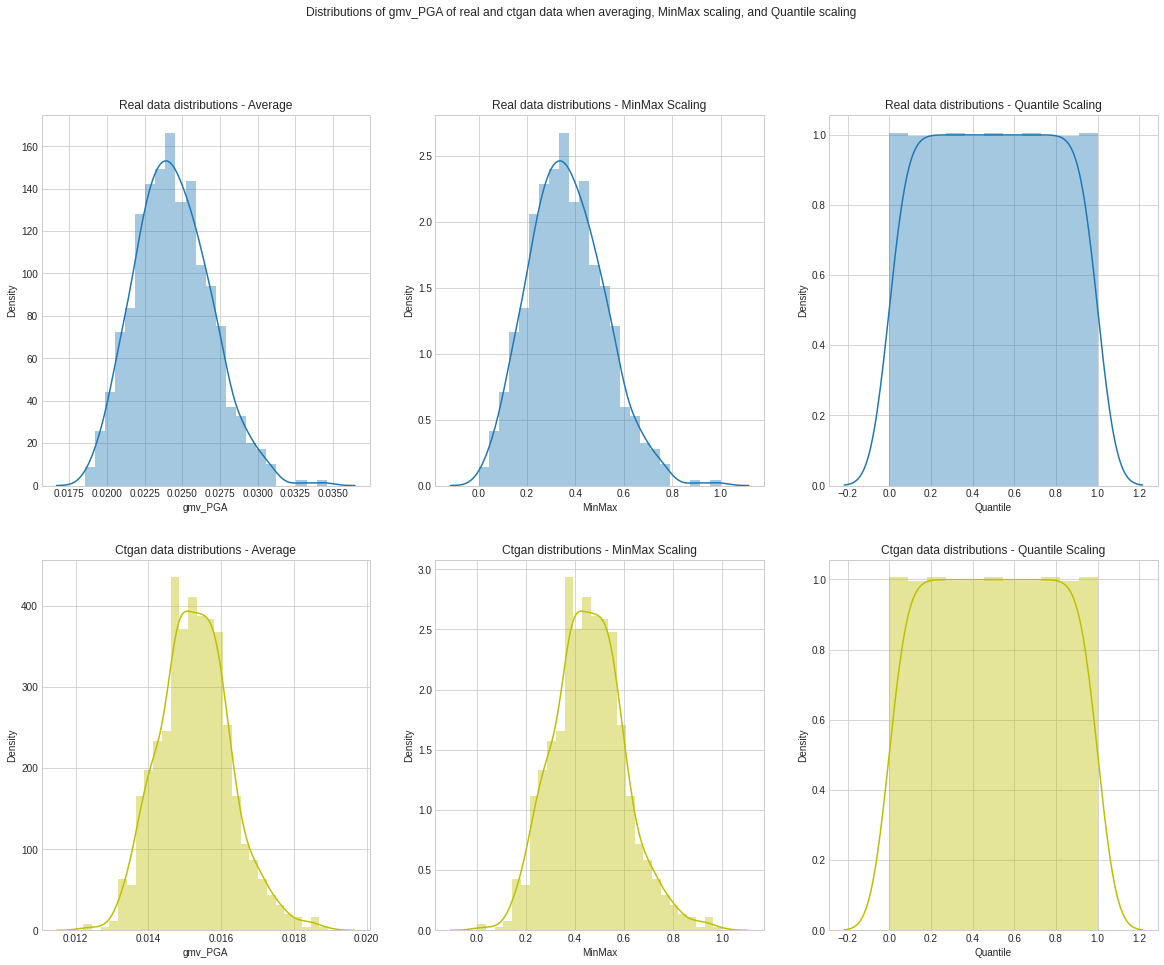

In [ ]:
# Plotting the distributions of PGA
dis_plot('gmv_PGA')

As we could see from the result, both real and ctgan data had nearly the same distributions when averaging, MinMax scaling, and Quantile scaling. Based on this, we could see that ctgan model learnt well on the distribution of the PGA variable. Next, we would check the result from mapping.

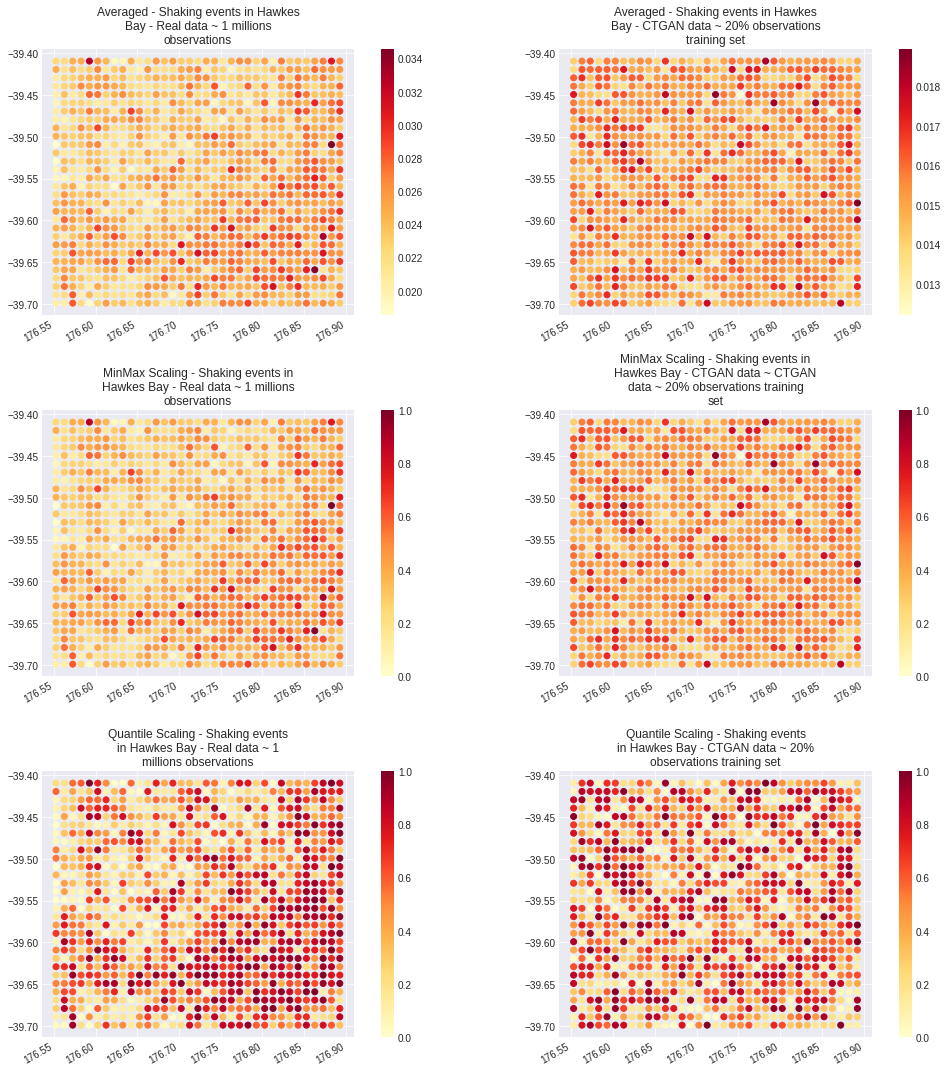

In [ ]:
# Mapping the patterns of PGA
mapping('gmv_PGA')

As we could notice, the results of mapping PGA were very poor for all three types. This fit with the results we had from the Correlation method. As mentioned above, this could be because the values of this variables were close to 0 which led to near-zero-variance issue and outliers.

### 6.4.2. Mapping Vs30

/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function 

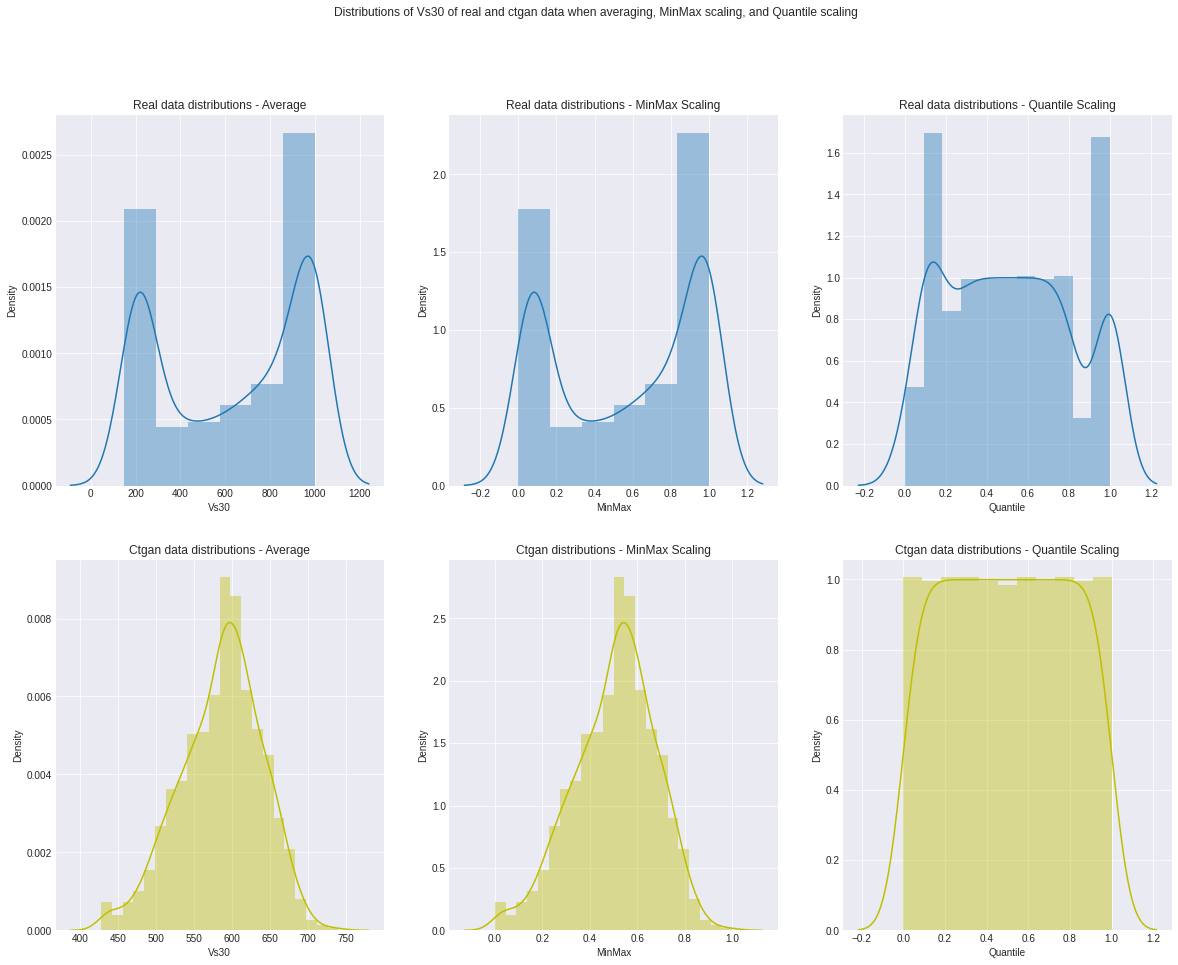

In [ ]:
# Plotting the distributions of PGA
dis_plot('Vs30')

As we could see from the result, ctgan data distributions for Vs30 had different results from real data when averaging, MinMax scaling, and Quantile scaling. Based on this, we could see that ctgan model did not learn well on the distribution of the Vs30 variable. Next, we would check the result from mapping.

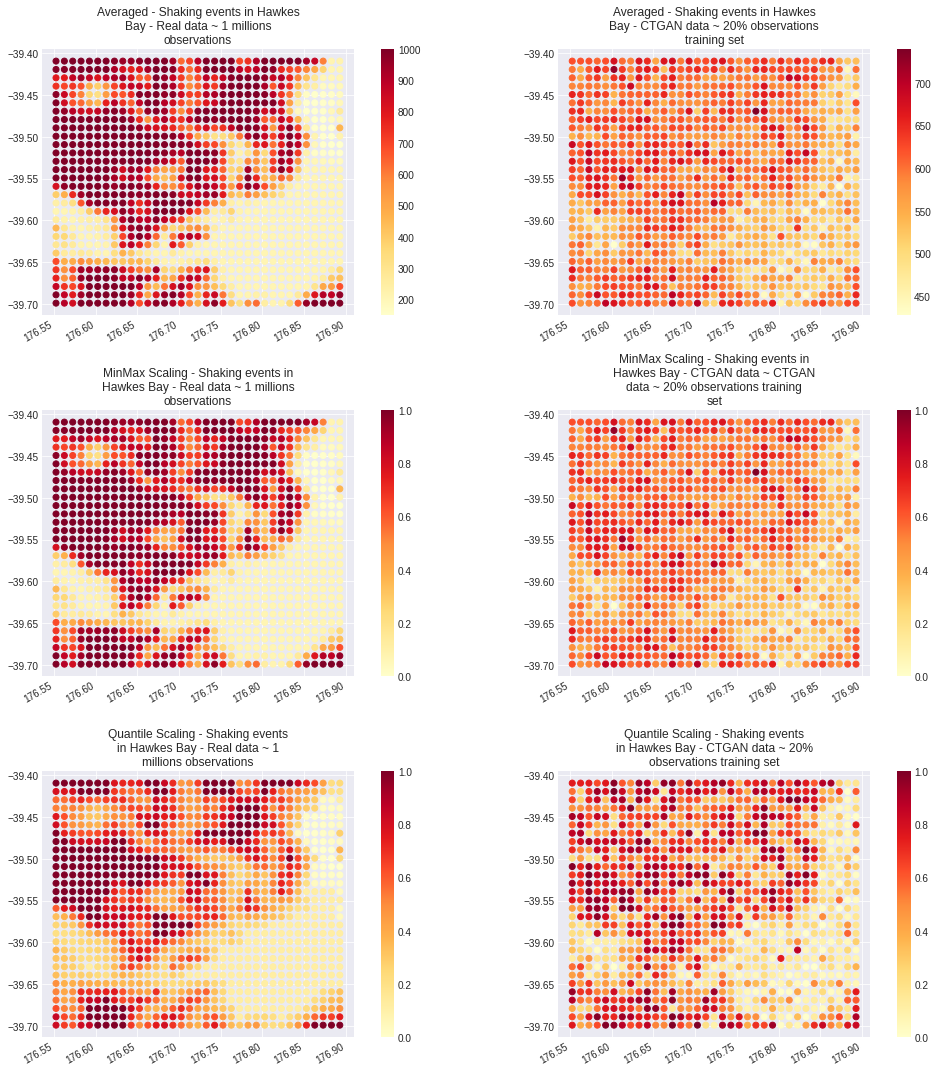

In [ ]:
# Mapping the patterns of PGA
mapping('Vs30')

As we could notice, the results of mapping Vs30 were very good for all three types. Especially, for Quantile scaling, we could see the patterns very clear. This also fit with the results we had from the Correlation method.

### 6.4.3. Mapping Z2.5

/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function 

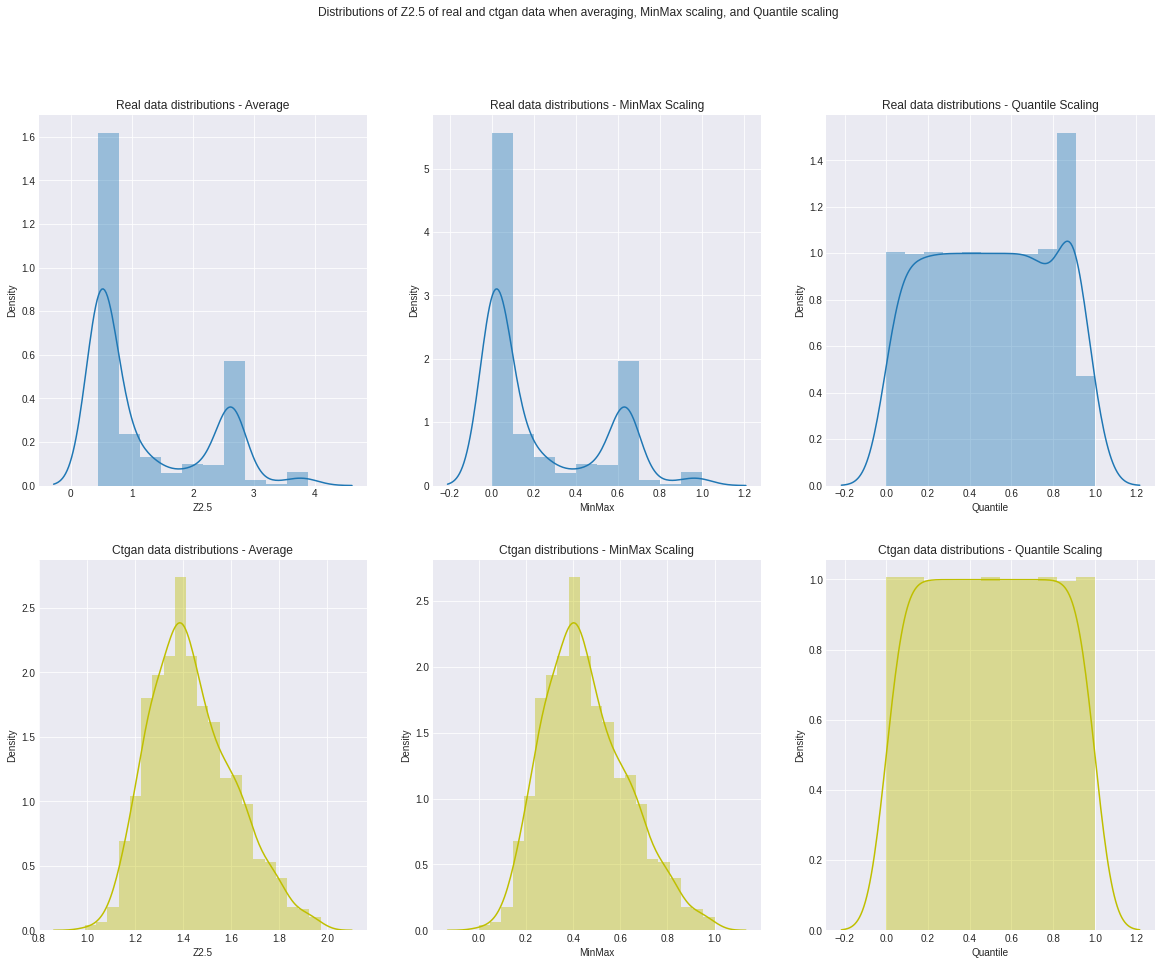

In [ ]:
# Plotting the distributions of PGA
dis_plot('Z2.5')

As we could see from the result, ctgan data distributions for Z2.5 had different results from real data when averaging, MinMax scaling, and Quantile scaling. Based on this, we could see that ctgan model did not learn well on the distribution of the Z2.5 variable. Next, we would check the result from mapping.

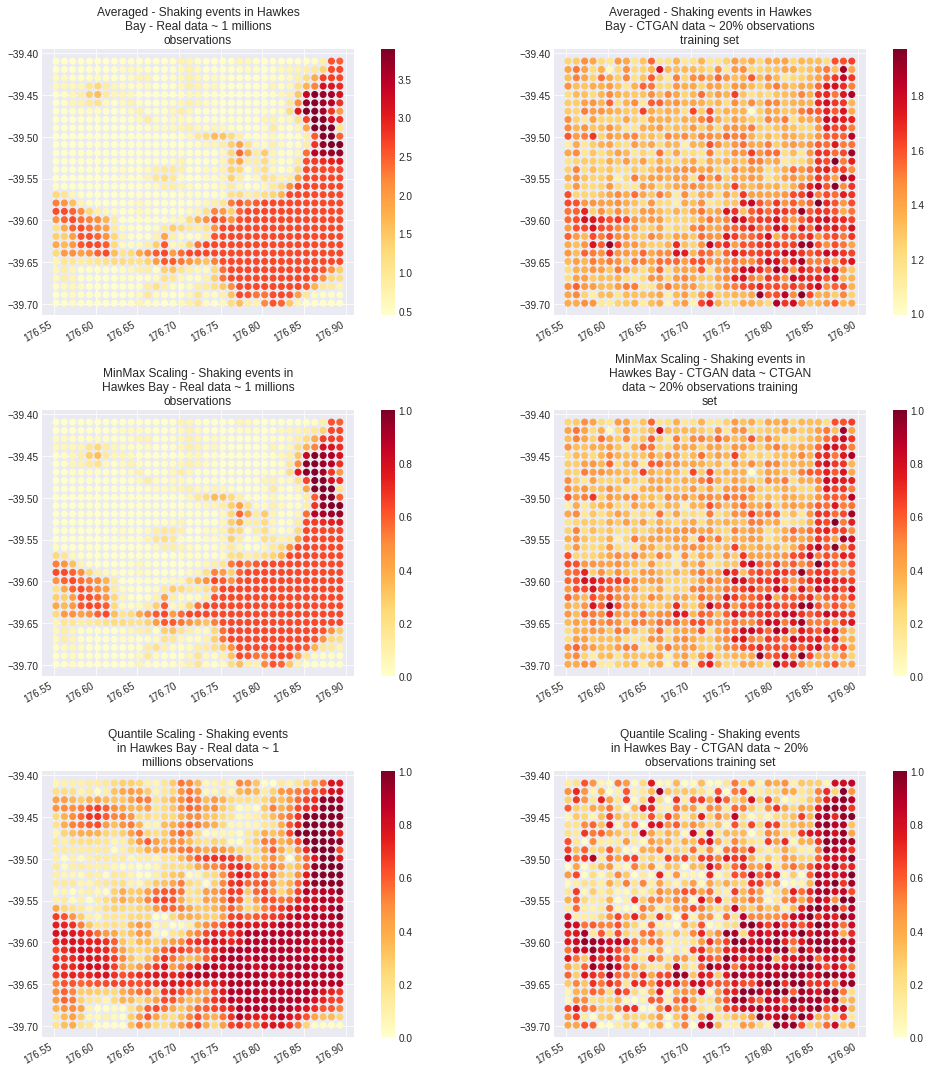

In [ ]:
# Mapping the patterns of PGA
mapping('Z2.5')

As we could notice, the results of mapping Z2.5 were very good for all three types. Especially, for Quantile scaling, we could see the patterns very clear. This also relatively fit with the results we had from the Correlation method.

### 6.4.4. Mapping Z1.0

/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function 

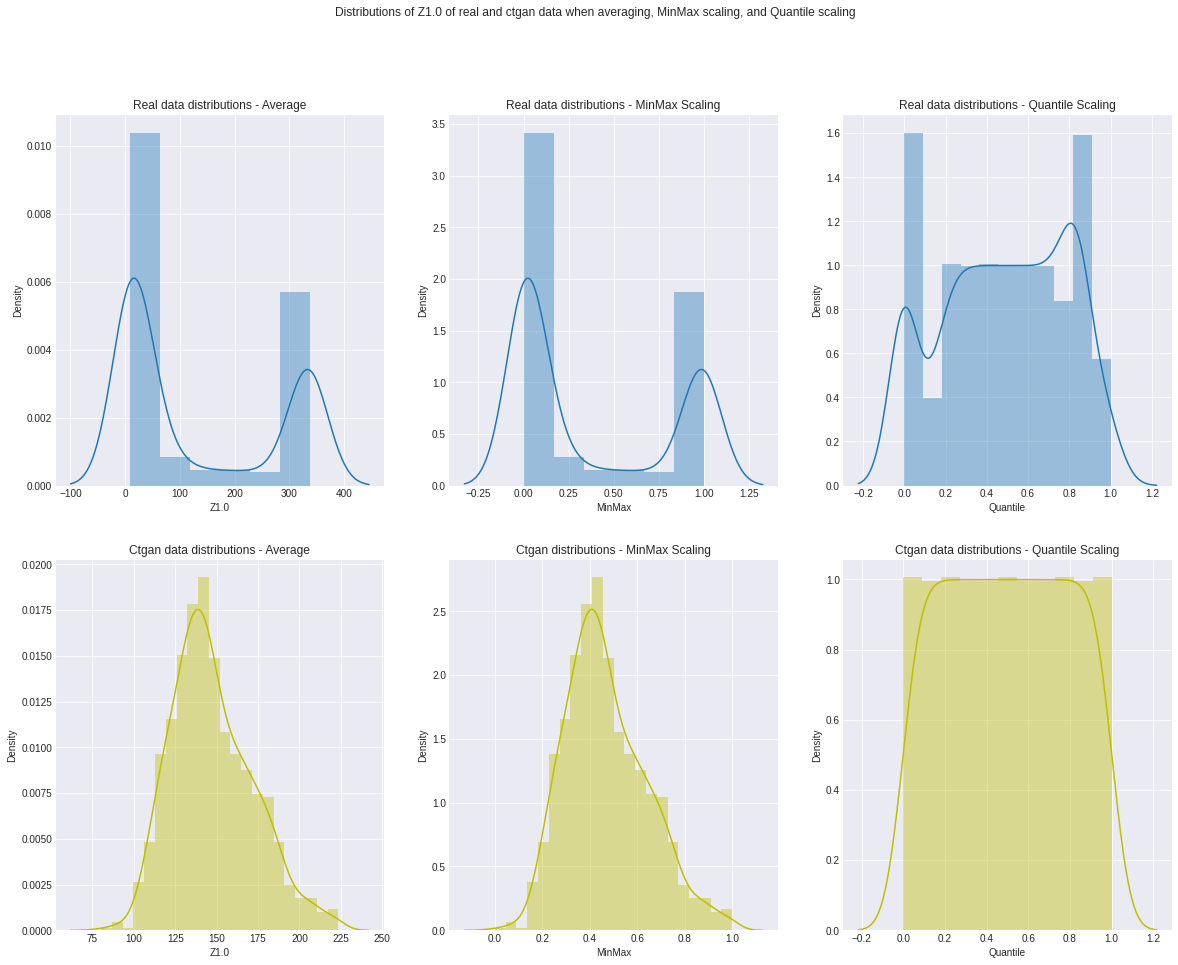

In [ ]:
# Plotting the distributions of PGA
dis_plot('Z1.0')

As we could see from the result, ctgan data distributions for Z1.0 had different results from real data when averaging, MinMax scaling, and Quantile scaling. Based on this, we could see that ctgan model did not learn well on the distribution of the Z1.0 variable. Next, we would check the result from mapping.

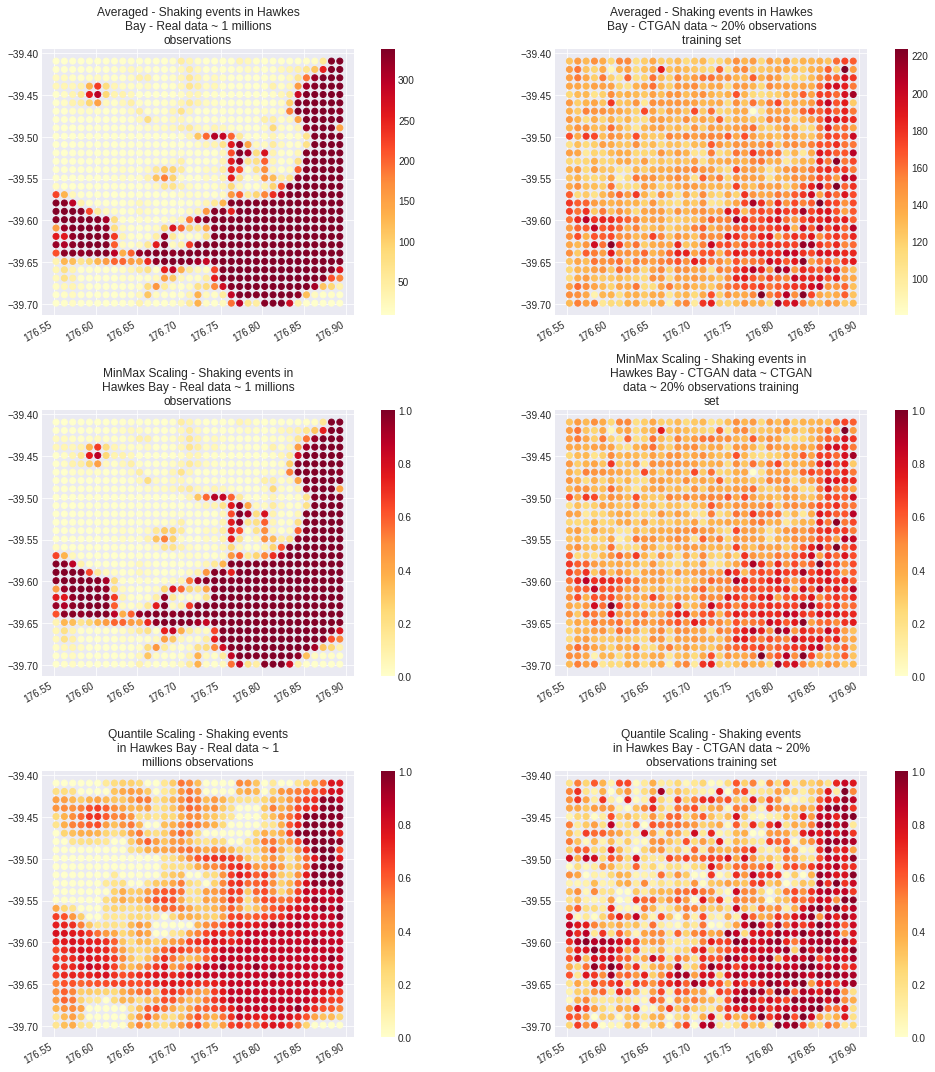

In [ ]:
# Mapping the patterns of PGA
mapping('Z1.0')

As we could notice, the results of mapping Z1.0 were very good for all three types. Especially, for Quantile scaling, we could see the patterns very clear. This also relatively fit with the results we had from the Correlation method.